# Corrigé du TP : analyser des appels de centre de contact

Solution complète du TP, exécutée de bout en bout sur le corpus entier. Les réponses aux questions de réflexion sont rédigées sous chaque question.

**Ce qui a été exécuté.** Les parties 0 à 9 ont tourné sur les 1 446 appels : tous les chiffres et graphiques affichés viennent de cette exécution, avec les versions de bibliothèques affichées par la cellule 0.3. Le notebook a aussi été rejoué en entier avec des versions plus anciennes (scikit-learn 1.2, pandas 2.2, numpy 1.26) : toutes les vérifications passent, et les scores bougent de un à trois centièmes parce que la composition des plis change d'une version de scikit-learn à l'autre. Les réponses rédigées ne retiennent que les conclusions qui tiennent dans les deux cas. La partie 10 (Whisper, wav2vec 2.0, plongements de phrases) n'a pas pu être exécutée pendant la préparation, faute de carte graphique et d'accès aux modèles : son code suit l'usage courant des bibliothèques mais n'a pas été vérifié sur de vrais modèles.

**Rappel sur l'étiquette.** Ce corpus ne contient pas de mesure fiable de la satisfaction. L'étiquette de travail est la tonalité attribuée par un outil automatique. Les scores ci-dessous disent à quel point on sait reproduire cet outil, pas à quel point on sait mesurer la satisfaction.

## Partie 0 : mise en route

Exécute ces trois cellules sans les modifier. La première télécharge le corpus (environ 650 Mo à télécharger, 3 Go sur le disque : compte quelques minutes, sans affichage intermédiaire), la deuxième installe deux bibliothèques, la troisième charge les outils du TP.

In [1]:
# 0.1  Récupérer le corpus (une seule fois par session)
import os, subprocess, time
from pathlib import Path

SUR_KAGGLE = Path("/kaggle").exists()

def dossier_de_travail():
    """Un dossier temporaire où l'on peut écrire (hors de /kaggle/working pour ne pas alourdir les sauvegardes)."""
    for base in ([Path("/kaggle/temp"), Path("/tmp")] if SUR_KAGGLE else [Path.cwd()]):
        try:
            base.mkdir(parents=True, exist_ok=True)
            return base
        except OSError:
            continue
    return Path.cwd()

RACINE = Path(os.environ.get("HVB_DIR", dossier_de_travail() / "harper-valley"))
if not (RACINE / "data" / "metadata").exists():
    debut = time.time()
    print("téléchargement du corpus en cours, patiente quelques minutes...")
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/cricketclub/gridspace-stanford-harper-valley", str(RACINE)], check=True)
    print(f"corpus téléchargé en {time.time() - debut:.0f} s")
DONNEES = RACINE / "data"
print(len(list((DONNEES / "metadata").glob("*.json"))), "appels disponibles")

1446 appels disponibles


In [2]:
# 0.2  Deux bibliothèques absentes de Kaggle par défaut : descripteurs acoustiques et taux d'erreur de mots
%pip install -q opensmile jiwer

In [3]:
# 0.3  Imports et outils du TP (à exécuter sans modifier)
import json, re, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import resample_poly
from IPython.display import Audio, display

warnings.filterwarnings("ignore", category=FutureWarning)          # annonces de changements à venir dans les bibliothèques
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 100)

# Dossier où ranger les calculs longs pour ne pas les refaire
CACHE = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path.cwd()

# ---------------------------------------------------------------- vérifications
def verifier(nom, test, indice=""):
    """Affiche [OK] si test() renvoie vrai, sinon [À revoir] et un indice. Ne lève jamais d'erreur, ne renvoie rien."""
    try:
        reussi, detail = bool(test()), ""
    except Exception as erreur:
        reussi, detail = False, f" ({type(erreur).__name__} : {str(erreur)[:90]})"
    if reussi:
        print(f"[OK]        {nom}")
    else:
        print(f"[À revoir]  {nom}{detail}" + (f"\n            Indice : {indice}" if indice else ""))

def proche(valeur, cible, tolerance):
    """Vrai si valeur est à moins de tolerance de cible."""
    return abs(float(valeur) - cible) <= tolerance

# ---------------------------------------------------------------- graphiques
BLEU, ORANGE, VERT, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#b9b7af"
ENCRE, ENCRE_2, DISCRET, GRILLE, FOND = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND, "figure.dpi": 110,
    "font.family": "sans-serif", "font.size": 10.5, "text.color": ENCRE,
    "axes.labelcolor": ENCRE_2, "xtick.color": DISCRET, "ytick.color": ENCRE_2,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "xtick.major.size": 0, "ytick.major.size": 0, "legend.frameon": False,
})

def tracer_barres(valeurs, titre, format_valeur="{:.0%}", accent=None):
    """Barres horizontales triées, valeur écrite au bout de chaque barre.
    valeurs : Series (index = libellés). accent : libellé à mettre en avant, les autres passent en gris."""
    v = valeurs.sort_values()
    fig, ax = plt.subplots(figsize=(7.6, 0.42 * len(v) + 1.2))
    couleurs = [BLEU if accent is None or k == accent else GRIS for k in v.index]
    ax.barh([str(k) for k in v.index], v.values, height=0.55, color=couleurs)
    for i, x in enumerate(v.values):
        ax.text(max(x, 0), i, "  " + format_valeur.format(x), va="center", ha="left", color=ENCRE, fontsize=10)
    ax.set_title(titre)
    ax.set_xlim(min(0, v.min() * 1.15), max(v.max(), 1e-9) * 1.18)
    ax.set_xticks([]); ax.grid(False); ax.spines["bottom"].set_visible(False)
    plt.show()

def tracer_grille(tableau, titre, format_valeur="{:+.2f}"):
    """Tableau à deux entrées en couleurs : plus la case est foncée, plus la valeur est haute. Lignes et colonnes triées par moyenne."""
    from matplotlib.colors import LinearSegmentedColormap
    t = tableau.loc[tableau.mean(axis=1).sort_values().index, tableau.mean(axis=0).sort_values().index]
    valeurs = np.ma.masked_invalid(t.values.astype(float))
    bas, haut = float(valeurs.min()), float(valeurs.max())
    fig, ax = plt.subplots(figsize=(0.8 * t.shape[1] + 1.6, 0.42 * t.shape[0] + 1.4))
    ax.pcolormesh(valeurs, cmap=LinearSegmentedColormap.from_list("bleus", [FOND, BLEU]), vmin=bas, vmax=haut, edgecolors=FOND, linewidth=2)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            if np.ma.is_masked(valeurs[i, j]):
                ax.text(j + 0.5, i + 0.5, "vide", ha="center", va="center", fontsize=8.5, color=DISCRET, style="italic")
            else:
                fonce = (valeurs[i, j] - bas) / max(haut - bas, 1e-9) > 0.62
                ax.text(j + 0.5, i + 0.5, format_valeur.format(valeurs[i, j]), ha="center", va="center", fontsize=9, color="white" if fonce else ENCRE)
    ax.set_xticks(np.arange(t.shape[1]) + 0.5); ax.set_xticklabels(t.columns)
    ax.set_yticks(np.arange(t.shape[0]) + 0.5); ax.set_yticklabels(t.index)
    ax.invert_yaxis(); ax.grid(False); ax.set_title(titre)
    for cote in ("left", "bottom"):
        ax.spines[cote].set_visible(False)
    plt.show()

def tracer_colonnes(valeurs, titre, ylabel="", etiquettes=True, format_valeur="{:.0f}"):
    """Colonnes dans l'ordre de l'index (catégories ordonnées). etiquettes=False masque les libellés de l'axe horizontal."""
    fig, ax = plt.subplots(figsize=(7.6, 3.2))
    x = np.arange(len(valeurs))
    ax.bar(x, valeurs.values, width=0.62, color=BLEU)
    ax.set_title(titre); ax.set_ylabel(ylabel); ax.grid(axis="x", visible=False)
    if etiquettes:
        ax.set_xticks(x); ax.set_xticklabels([str(k) for k in valeurs.index])
        for i, v in enumerate(valeurs.values):
            ax.text(i, v, format_valeur.format(v), ha="center", va="bottom", color=ENCRE, fontsize=9.5)
    else:
        ax.set_xticks([])
    plt.show()

def montrer_appel(sid):
    """Le signal des deux canaux d'un appel, avec les tours de parole en surbrillance, sur l'horloge commune aux deux canaux."""
    t = tours[tours.sid == sid]
    fig, axes = plt.subplots(2, 1, figsize=(10, 3.8), sharex=True)
    for ax, canal, couleur in zip(axes, (1, 2), (BLEU, ORANGE)):
        signal, sr = sf.read(str(fichier_audio(sid, canal)), dtype="float32")
        tc = t[t.canal == canal]
        decalage = float((tc.position_s - tc.debut_s).median()) if len(tc) else 0.0   # position dans le fichier -> horloge commune
        ax.plot(np.arange(len(signal))[::4] / sr - decalage, signal[::4], color=couleur, linewidth=0.5)
        for tour in tc.itertuples():
            ax.axvspan(tour.debut_s, tour.debut_s + tour.duree_s, color=couleur, alpha=0.13, linewidth=0)
        roles = " et ".join(sorted(tc.role.unique())) or "aucun tour"
        ax.set_title(f"Canal {canal} : {roles}", fontsize=10.5, pad=4)
        ax.set_yticks([]); ax.grid(False); ax.spines["left"].set_visible(False)
    axes[-1].set_xlabel("temps dans la conversation (s)")
    fig.suptitle(f"Appel {sid}", x=0.125, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

def ecouter(sid, canal, position_s=0.0, duree_s=15.0):
    """Un extrait d'un des deux fichiers audio de l'appel : duree_s secondes à partir de position_s (position dans le fichier)."""
    chemin = fichier_audio(sid, canal)
    sr = sf.info(str(chemin)).samplerate
    signal, _ = sf.read(str(chemin), start=int(position_s * sr), frames=int(duree_s * sr), dtype="float32")
    return Audio(signal, rate=sr)

def tracer_ablation(tableau, repere=None, titre="Étude d'ablation : AUC hors pli selon les branches utilisées"):
    """tableau : index = combinaison de branches, colonne AUC, et si possible colonnes bas / haut (intervalle à 95 %).
    repere : AUC d'un modèle de référence, tracée en pointillés."""
    t = tableau.sort_values("AUC")
    fig, ax = plt.subplots(figsize=(7.6, 0.45 * len(t) + 1.5))
    complet = max(t.index, key=len)
    for i, (nom, ligne) in enumerate(t.iterrows()):
        couleur = BLEU if nom == complet else GRIS
        if "bas" in t.columns:
            ax.plot([ligne["bas"], ligne["haut"]], [i, i], color=couleur, linewidth=2, solid_capstyle="round")
        ax.plot(ligne["AUC"], i, "o", color=couleur, markersize=8, markeredgecolor=FOND, markeredgewidth=2)
        ax.text(ligne["haut"] if "haut" in t.columns else ligne["AUC"], i, f"   {ligne['AUC']:.3f}", va="center", color=ENCRE, fontsize=10)
    ax.axvline(0.5, color="#c3c2b7", linewidth=1)
    ax.text(0.5, -0.72, "hasard ", color=DISCRET, fontsize=9, va="center", ha="right")
    if repere is not None:
        ax.axvline(repere, color=DISCRET, linewidth=1, linestyle=(0, (4, 3)))
        ax.text(repere, -0.72, " motif seul", color=DISCRET, fontsize=9, va="center", ha="left")
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.set_ylim(-1.0, len(t) - 0.4)
    ax.set_xlim(0.4, 1.0); ax.set_xlabel("AUC (0,5 = hasard, 1 = parfait)"); ax.set_title(titre)
    ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False)
    plt.show()

def tracer_trajectoire(trajectoire, titre, ylabel):
    """trajectoire : index = début / milieu / fin, une colonne par groupe d'appels (deux groupes au plus)."""
    fig, ax = plt.subplots(figsize=(6.4, 3.4))
    for colonne, couleur in zip(trajectoire.columns, (ORANGE, BLEU)):
        ax.plot(range(len(trajectoire)), trajectoire[colonne].values, "-o", color=couleur, linewidth=2,
                markersize=8, markeredgecolor=FOND, markeredgewidth=2, label=str(colonne))
        ax.text(len(trajectoire) - 1, trajectoire[colonne].values[-1], f"   {trajectoire[colonne].values[-1]:.2f}", va="center", color=ENCRE)
    ax.set_xticks(range(len(trajectoire))); ax.set_xticklabels(trajectoire.index)
    ax.set_xlim(-0.2, len(trajectoire) - 0.55); ax.set_ylabel(ylabel); ax.set_title(titre)
    ax.grid(axis="x", visible=False); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
    plt.show()

import sys, sklearn, scipy, matplotlib
print("Outils chargés. Versions : Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Outils chargés. Versions : Python 3.11.15 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.17.1 | matplotlib 3.11.2


## Partie 1 : contrôle à la réception

Avant tout modèle, on vérifie ce qu'on a reçu. Le corpus est rangé ainsi :

```
data/audio/caller/<sid>.wav     un fichier par appel
data/audio/agent/<sid>.wav      un fichier par appel
data/metadata/<sid>.json        une fiche par appel (qui, quand, quelle tâche, questionnaire après l'appel)
data/transcript/<sid>.json      la liste des tours de parole de l'appel
```

`sid` est l'identifiant de l'appel. La cellule suivante affiche une fiche et un tour de parole bruts : lis-les avant de commencer.

In [4]:
premiere_fiche = sorted((DONNEES / "metadata").glob("*.json"))[0]
fiche = json.loads(premiere_fiche.read_text())
segments = json.loads((DONNEES / "transcript" / premiere_fiche.name).read_text())

print("Clés d'une fiche :", list(fiche))
print("\nCôté client (caller) :", json.dumps(fiche["caller"], indent=1))
print("\nUn tour de parole :", json.dumps({k: v for k, v in segments[0].items() if not k.startswith("word_")}, indent=1))

Clés d'une fiche : ['agent', 'caller', 'end_time_ms', 'sid', 'start_time_ms', 'labels', 'session', 'tasks']

Côté client (caller) : {
 "arrival_time_ms": 1591056775485,
 "hangup_time_ms": 1591056842795,
 "metadata": {
  "first and last name": "Patricia Brown"
 },
 "responses": [
  {
   "submit_time_ms": 1591056823619
  }
 ],
 "speaker_id": 44,
 "survey_response": {
  "submit_time_ms": 1591056826312,
  "data": {
   "ease_of_connection": "10",
   "partner_rating": "10"
  }
 }
}

Un tour de parole : {
 "channel_index": 2,
 "dialog_acts": [
  "gridspace_greeting"
 ],
 "duration_ms": 2670,
 "emotion": {
  "neutral": 0.3138437271118164,
  "negative": 0.021983588114380836,
  "positive": 0.6641727089881897
 },
 "human_transcript": "hello this is harper valley national bank",
 "index": 1,
 "offset_ms": 3720,
 "speaker_role": "agent",
 "start_ms": 1669,
 "start_timestamp_ms": 1591056787005,
 "transcript": "hello mr harper valley national bank"
}


### Exercice 1.1 : charger les appels et les tours de parole

Construis deux tableaux.

`appels`, une ligne par appel, indexé par `sid` :

| colonne | contenu | où le trouver |
|---|---|---|
| `motif` | la tâche confiée au client | `tasks[0]["task_type"]` |
| `id_client`, `id_conseiller` | identifiants de locuteur | `caller["speaker_id"]`, `agent["speaker_id"]` |
| `duree_s` | durée de la conversation en secondes | `end_time_ms` moins `start_time_ms` |
| `attente_s` | attente du client avant la mise en relation | `start_time_ms` moins `caller["arrival_time_ms"]` |
| `note_client` | note laissée par le client après l'appel | déjà écrit dans le squelette |
| `nom_client`, `nom_conseiller` | noms fictifs joués pendant l'appel | déjà écrits |

`tours`, une ligne par tour de parole :

| colonne | contenu | où le trouver |
|---|---|---|
| `rang` | numéro d'ordre du tour dans l'appel | déjà écrit |
| `role` | `"client"` ou `"conseiller"` | `speaker_role` vaut `"caller"` ou `"agent"` |
| `canal` | 1 ou 2 | `channel_index` |
| `start_s` | premier champ de temps du tour | `start_ms` |
| `offset_s` | second champ de temps du tour | `offset_ms` |
| `duree_s` | durée du tour | `duration_ms` |
| `horodatage_ms` | heure réelle du début du tour, laissée en millisecondes | déjà écrit |
| `texte`, `texte_auto` | transcription humaine, transcription automatique | déjà écrits |
| `p_neg`, `p_neu`, `p_pos` | sortie de l'outil d'analyse de tonalité | déjà écrits |

Toutes les durées sont en millisecondes dans les fichiers : convertis en secondes. Chaque tour porte deux champs de temps, `start_ms` et `offset_ms`. Garde-les tous les deux sous leur nom d'origine : l'exercice 1.3 dira lequel sert à quoi.

In [5]:
lignes_appels, lignes_tours = [], []
for fichier in sorted((DONNEES / "metadata").glob("*.json")):
    fiche = json.loads(fichier.read_text())
    sid = fiche["sid"]
    client, conseiller = fiche["caller"], fiche["agent"]
    enquete = (client.get("survey_response") or {}).get("data") or {}
    note = enquete.get("partner_rating")
    lignes_appels.append({
        "sid": sid,
        "motif": fiche["tasks"][0]["task_type"],
        "id_client": client["speaker_id"],
        "id_conseiller": conseiller["speaker_id"],
        "duree_s": (fiche["end_time_ms"] - fiche["start_time_ms"]) / 1000,
        "attente_s": (fiche["start_time_ms"] - client["arrival_time_ms"]) / 1000,
        "note_client": float(note) if note not in (None, "") else np.nan,
        "nom_client": client["metadata"]["first and last name"],
        "nom_conseiller": conseiller["metadata"]["agent_name"],
    })
    for seg in json.loads((DONNEES / "transcript" / f"{sid}.json").read_text()):
        lignes_tours.append({
            "sid": sid,
            "rang": seg["index"],
            "role": "client" if seg["speaker_role"] == "caller" else "conseiller",
            "canal": seg["channel_index"],
            "start_s": seg["start_ms"] / 1000,
            "offset_s": seg["offset_ms"] / 1000,
            "duree_s": seg["duration_ms"] / 1000,
            "horodatage_ms": seg["start_timestamp_ms"],
            "texte": seg["human_transcript"] or "",
            "texte_auto": seg["transcript"] or "",
            "p_neg": seg["emotion"]["negative"], "p_neu": seg["emotion"]["neutral"], "p_pos": seg["emotion"]["positive"],
        })

appels = pd.DataFrame(lignes_appels).set_index("sid")
tours = pd.DataFrame(lignes_tours).sort_values(["sid", "rang"]).reset_index(drop=True)
print(appels.shape, tours.shape)
appels.head(3)

(1446, 8) (25730, 13)


,motif,id_client,id_conseiller,duree_s,attente_s,note_client,nom_client,nom_conseiller
sid,,,,,,,,
0002f70f7386445b,replace card,44,46,51.203,7.706,10.0,Patricia Brown,Elizabeth
004860b1ab2e4c88,replace card,44,17,45.248,16.541,10.0,Mary Smith,Robert
0091a706bc604188,check balance,44,3,51.218,10.840,10.0,Elizabeth Davis,Jennifer


In [6]:
# Vérification 1.1
verifier("1 446 appels et 25 730 tours", lambda: len(appels) == 1446 and len(tours) == 25730)
verifier("les rôles sont « client » et « conseiller »", lambda: set(tours.role) == {"client", "conseiller"} and (tours.role == "client").sum() == 12433,
         "role vaut \"client\" quand speaker_role vaut \"caller\"")
verifier("durée médiane d'un appel proche de 56 s", lambda: proche(appels.duree_s.median(), 56.1, 0.3),
         "(end_time_ms - start_time_ms) / 1000")
verifier("attente médiane proche de 9 s", lambda: proche(appels.attente_s.median(), 9.3, 0.3),
         "start_time_ms moins l'arrivée du client, en secondes")
verifier("12 heures de parole au total", lambda: proche(tours.duree_s.sum() / 3600, 12.02, 0.05), "duration_ms / 1000")
verifier("les deux champs de temps sont en secondes", lambda: proche(tours.start_s.max(), 179.3, 0.5) and proche(tours.offset_s.max(), 180.8, 0.5),
         "start_ms / 1000 et offset_ms / 1000")
verifier("55 clients différents, 965 notes", lambda: appels.id_client.nunique() == 55 and appels.note_client.notna().sum() == 965)

[OK]        1 446 appels et 25 730 tours
[OK]        les rôles sont « client » et « conseiller »
[OK]        durée médiane d'un appel proche de 56 s
[OK]        attente médiane proche de 9 s
[OK]        12 heures de parole au total
[OK]        les deux champs de temps sont en secondes
[OK]        55 clients différents, 965 notes


### Exercice 1.2 : qui est sur quel canal ?

La documentation annonce : canal 1 pour le côté appelant, canal 2 pour le côté conseiller. Vérifie-le au lieu de le croire.

1. Pour chaque appel, calcule le canal sur lequel se trouvent les tours du client (le plus fréquent, par précaution). Range-le dans `appels["canal_client"]`.
2. Compte les appels où ce canal n'est pas le canal 1 : `n_inverses`.

In [7]:
appels["canal_client"] = tours[tours.role == "client"].groupby("sid").canal.agg(lambda c: c.mode().iat[0])
n_inverses = int((appels.canal_client != 1).sum())
print(n_inverses, "appels où le client n'est pas sur le canal 1")

37 appels où le client n'est pas sur le canal 1


In [8]:
# Vérification 1.2
verifier("canal du client calculé pour chaque appel", lambda: appels.canal_client.notna().all() and set(appels.canal_client) <= {1, 2},
         "tours[tours.role == \"client\"].groupby(\"sid\").canal puis le mode")
verifier("37 appels inversés", lambda: n_inverses == 37)

[OK]        canal du client calculé pour chaque appel
[OK]        37 appels inversés


### Exercice 1.3 : deux horloges

Chaque tour porte deux champs de temps. La documentation du corpus les décrit ainsi :

- `start_ms` : décalage du début du tour « depuis le début de la conversation » ;
- `offset_ms` : décalage du début du tour « depuis le début de l'enregistrement ».

Pour la suite, il te faut deux choses bien distinctes :

- la **position du tour dans son fichier audio**, pour découper le signal (branche B) ;
- une **horloge commune aux deux canaux**, pour savoir qui parle avant qui (branche C).

À lire la documentation, la position dans le fichier serait `offset_ms`. Vérifie-le par la mesure au lieu de le croire. La fonction `energie` est fournie : pendant un tour de parole, le signal est fort à l'endroit où se trouve vraiment la voix.

1. Calcule `tours["ecart_s"]`, la différence `offset_s - start_s`, et regarde sa distribution canal par canal.
2. Le squelette sélectionne mille tours du canal 2 pour lesquels les deux champs diffèrent, dans les appels non inversés (le canal 2 y est sans ambiguïté dans `audio/agent`). Pour chacun, mesure l'énergie du fichier à partir de `start_s`, puis à partir de `offset_s`, sur la durée du tour.
3. Calcule `part_start_plus_fort` : la part des tours où le signal est le plus fort à partir de `start_s`.

In [9]:
def energie(dossier, sid, position_s, duree_s):
    """Énergie moyenne (valeur efficace) d'un fichier audio, sur duree_s secondes à partir de position_s. dossier : "caller" ou "agent"."""
    chemin = DONNEES / "audio" / dossier / f"{sid}.wav"
    sr = sf.info(str(chemin)).samplerate
    signal, _ = sf.read(str(chemin), start=int(position_s * sr), frames=int(duree_s * sr), dtype="float32")
    return float(np.sqrt(np.mean(signal ** 2))) if len(signal) else 0.0

In [10]:
tours["ecart_s"] = tours.offset_s - tours.start_s
display(tours.groupby("canal").ecart_s.describe().round(2))

normaux = appels.index[appels.canal_client == 1]
echantillon = tours[tours.sid.isin(normaux) & (tours.canal == 2) & (tours.duree_s >= 1) & (tours.ecart_s.abs() > 0.5)].sample(1000, random_state=0)
e_start = np.array([energie("agent", r.sid, r.start_s, r.duree_s) for r in echantillon.itertuples()])
e_offset = np.array([energie("agent", r.sid, r.offset_s, r.duree_s) for r in echantillon.itertuples()])
part_start_plus_fort = float((e_start > e_offset).mean())
print(f"le signal est le plus fort à partir de start_s pour {part_start_plus_fort:.0%} des {len(echantillon)} tours testés")

,count,mean,std,min,25%,50%,75%,max
canal,,,,,,,,
1,12463.0,-0.00,0.00,-0.01,-0.0,0.00,0.00,0.00
2,13267.0,1.39,0.95,-0.02,0.0,2.01,2.04,2.59


le signal est le plus fort à partir de start_s pour 96% des 1000 tours testés


In [11]:
# Vérification 1.3
verifier("sur le canal 1 les deux champs coïncident", lambda: tours.ecart_s[tours.canal == 1].abs().max() < 0.05, "tours.offset_s - tours.start_s")
verifier("sur le canal 2 l'écart médian est d'environ 2 s", lambda: proche(tours.ecart_s[tours.canal == 2].median(), 2.01, 0.05),
         "offset_s moins start_s, dans ce sens")
verifier("mille tours mesurés aux deux positions", lambda: len(e_start) == len(e_offset) == 1000,
         "np.array([energie(\"agent\", r.sid, r.start_s, r.duree_s) for r in echantillon.itertuples()])")
verifier("la voix se trouve à la position start_s dans plus de 90 % des cas", lambda: part_start_plus_fort > 0.9, "(e_start > e_offset).mean()")

[OK]        sur le canal 1 les deux champs coïncident
[OK]        sur le canal 2 l'écart médian est d'environ 2 s
[OK]        mille tours mesurés aux deux positions
[OK]        la voix se trouve à la position start_s dans plus de 90 % des cas


La voix est donc à la position `start_s` : la documentation laissait attendre l'inverse. Reste à savoir lequel des deux champs est commun aux deux canaux. La cellule suivante le montre avec l'heure réelle de chaque tour (`horodatage_ms`) : si un champ est une horloge commune, « heure réelle moins champ » donne la même origine pour tous les tours d'un appel, quel que soit le canal.

In [12]:
for champ in ("start_s", "offset_s"):
    origine = tours.horodatage_ms - 1000 * tours[champ]
    etendue = origine.groupby(tours.sid).agg(lambda v: v.max() - v.min())
    print(f"{champ:<9} l'origine varie de {etendue.median():5.0f} ms (médiane) à l'intérieur d'un appel ; elle est stable dans {np.mean(etendue < 50):.0%} des appels")

start_s   l'origine varie de  2011 ms (médiane) à l'intérieur d'un appel ; elle est stable dans 30% des appels
offset_s  l'origine varie de     0 ms (médiane) à l'intérieur d'un appel ; elle est stable dans 100% des appels


À toi de conclure : range chaque champ dans la colonne qui porte son vrai rôle. Toute la suite du TP utilise ces deux colonnes.

In [13]:
tours["position_s"] = tours.start_s       # où lire le tour dans le fichier audio de son canal
tours["debut_s"] = tours.offset_s         # quand le tour commence, sur l'horloge commune aux deux canaux
tours = tours.sort_values(["sid", "debut_s", "rang"]).reset_index(drop=True)

In [14]:
# Vérification 1.3, conclusion
verifier("position_s est le champ où se trouve la voix", lambda: np.allclose(tours.position_s, tours.start_s),
         "la mesure d'énergie désigne start_s")
verifier("debut_s est le champ commun aux deux canaux", lambda: np.allclose(tours.debut_s, tours.offset_s),
         "seul offset_s a la même origine pour tous les tours d'un appel")
verifier("les tours sont triés dans l'ordre de la conversation", lambda: tours.groupby("sid").debut_s.apply(lambda d: d.is_monotonic_increasing).all())

[OK]        position_s est le champ où se trouve la voix
[OK]        debut_s est le champ commun aux deux canaux
[OK]        les tours sont triés dans l'ordre de la conversation


**Réflexion 1.3.** Qu'aurait coûté l'erreur si tu avais suivi la documentation ? Se serait-elle vue ?

In [15]:
# Durée pendant laquelle les deux canaux parlent en même temps, selon le champ pris pour horloge commune
def parole_simultanee(champ):
    total = 0.0
    for _, d in tours.groupby("sid"):
        a, b = d[d.canal == 1], d[d.canal == 2]
        debut_a, fin_a = a[champ].values[:, None], (a[champ] + a.duree_s).values[:, None]
        debut_b, fin_b = b[champ].values[None, :], (b[champ] + b.duree_s).values[None, :]
        total += np.clip(np.minimum(fin_a, fin_b) - np.maximum(debut_a, debut_b), 0, None).sum()
    return total

print(f"parole simultanée sur tout le corpus : {parole_simultanee('start_s'):.0f} s avec start_s, {parole_simultanee('offset_s'):.0f} s avec offset_s")
print(f"part des appels où le canal 2 est décalé de plus d'une demi-seconde : {(tours[tours.canal == 2].groupby('sid').ecart_s.median() > 0.5).mean():.0%}")

parole simultanée sur tout le corpus : 2013 s avec start_s, 1007 s avec offset_s
part des appels où le canal 2 est décalé de plus d'une demi-seconde : 70%


**Réponse.** Dans 70 % des appels, le fichier du canal 2 commence environ deux secondes après celui du canal 1. `start_ms` compte depuis le début du fichier du canal, `offset_ms` depuis une origine commune aux deux canaux (le début de l'appel). Les noms des champs et leur description suggèrent l'inverse.

- En prenant `offset_ms` pour la position dans le fichier, on aurait découpé le canal 2 deux secondes trop tard dans 70 % des appels. Dans ce TP, cela aurait faussé la voix du client dans les appels inversés, et toute analyse de la voix du conseiller. Aucun message d'erreur : un extrait décalé reste un extrait audio, et les descripteurs de voix se calculent très bien sur du silence ou sur le début de la phrase suivante.
- En prenant `start_ms` pour l'horloge commune, on aurait avancé le canal 2 de deux secondes par rapport au canal 1. La parole simultanée des deux interlocuteurs, mesurée sur tout le corpus, double (2 013 s au lieu de 1 007 s) : tous les indicateurs de la branche C sur qui coupe qui et sur les temps de réponse auraient été faux.

Le piège est réel : une première version de ce corrigé suivait la documentation, et c'est le graphique de l'exercice 1.5 qui a montré le décalage entre le signal et les zones colorées. Deux règles à retenir. Un champ de temps se vérifie toujours contre le signal. Et un graphique des données brutes attrape des erreurs qu'aucun test numérique n'avait prévues.

### Exercice 1.4 : dans quel fichier est la voix du client ?

Reviens aux 37 appels inversés de l'exercice 1.2. Deux hypothèses :

- les fichiers sont rangés **par rôle** : la voix du client est dans `audio/caller`, comme partout ;
- les fichiers sont rangés **par canal** : `audio/caller` contient le canal 1, donc ici la voix du conseiller.

Même méthode : pendant un tour du client, le fichier qui contient sa voix est le plus fort.

1. Prends les tours du client d'au moins une seconde dans les appels inversés.
2. Pour chacun, calcule l'énergie dans `caller` et dans `agent`, à partir de `position_s` et sur la durée `duree_s`.
3. Calcule `part_agent_plus_fort`, la part des tours où le fichier `agent` est le plus fort.

In [16]:
inverses = appels.index[appels.canal_client != 1]
a_tester = tours[tours.sid.isin(inverses) & (tours.role == "client") & (tours.duree_s >= 1)]
e_caller = np.array([energie("caller", r.sid, r.position_s, r.duree_s) for r in a_tester.itertuples()])
e_agent = np.array([energie("agent", r.sid, r.position_s, r.duree_s) for r in a_tester.itertuples()])
part_agent_plus_fort = float((e_agent > e_caller).mean())
print(f"{len(a_tester)} tours testés ; le fichier « agent » est le plus fort dans {part_agent_plus_fort:.0%} des cas")

162 tours testés ; le fichier « agent » est le plus fort dans 89% des cas


In [17]:
# Vérification 1.4
verifier("162 tours testés", lambda: len(a_tester) == 162, "rôle client, durée d'au moins 1 s, sid parmi inverses")
verifier("la voix du client est dans « agent » pour la grande majorité des tours testés", lambda: part_agent_plus_fort > 0.8,
         "pour chaque tour r de a_tester : energie(\"agent\", r.sid, r.position_s, r.duree_s)")

[OK]        162 tours testés
[OK]        la voix du client est dans « agent » pour la grande majorité des tours testés


Conclus : écris `fichier_audio(sid, canal)`, qui renvoie le chemin du fichier contenant ce canal de cet appel.

In [18]:
def fichier_audio(sid, canal):
    """Les fichiers sont rangés par canal : canal 1 dans audio/caller, canal 2 dans audio/agent."""
    return DONNEES / "audio" / ("caller" if canal == 1 else "agent") / f"{sid}.wav"

In [19]:
# Vérification 1.4, conclusion
verifier("fichier_audio range par canal", lambda: Path(fichier_audio("x", 1)).parent.name == "caller" and Path(fichier_audio("x", 2)).parent.name == "agent",
         "canal 1 -> dossier caller, canal 2 -> dossier agent, quel que soit le rôle")
verifier("le fichier existe pour un vrai appel", lambda: Path(fichier_audio(appels.index[0], 2)).exists(),
         "DONNEES / \"audio\" / dossier / f\"{sid}.wav\"")

[OK]        fichier_audio range par canal
[OK]        le fichier existe pour un vrai appel


**Réflexion 1.4.** Que se serait-il passé pour la branche « voix » si tu avais choisi le fichier d'après le rôle, sans faire ce contrôle ?

**Réponse.** Dans 37 appels (2,6 %), on aurait calculé les descripteurs de voix du client sur la voix du conseiller, sans aucun message d'erreur. Le modèle aurait appris sur un peu de données fausses et personne ne l'aurait vu. C'est le sens du contrôle à la réception : la documentation décrit le cas général, les données contiennent les exceptions. La règle retenue est donc : le fichier se choisit par le canal, le rôle se lit dans la transcription.

Contrôle complémentaire fait pendant la préparation : dans ces 37 appels, c'est bien le conseiller qui prononce la formule d'accueil de la banque (36 appels sur 37), et un classifieur de locuteur entraîné sur les autres appels reconnaît le client attendu sur le canal 2 dans 33 cas sur 37, jamais sur le canal 1. Les rôles et les identifiants de locuteur de la fiche sont donc justes : seuls les canaux sont échangés.

### Exercice 1.5 : regarder et écouter un appel

Rien à coder ici. Les deux outils `montrer_appel` et `ecouter` utilisent ta fonction `fichier_audio`. Modifie librement la cellule : change `sid_exemple` pour regarder trois ou quatre appels différents (`appels.index[10]`, `appels.index[200]`...), et les arguments de `ecouter` pour entendre l'autre canal ou un autre moment. Puis réponds à la question.

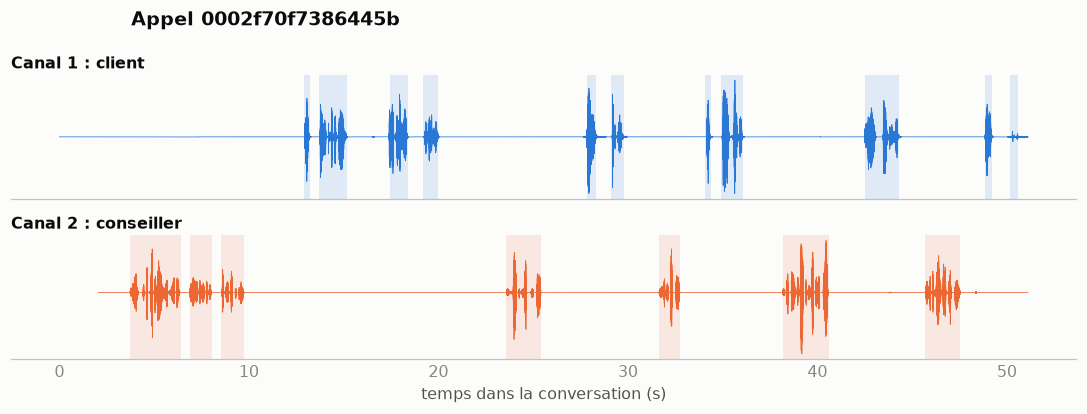

,role,canal,debut_s,duree_s,texte,texte_auto
0,conseiller,2,3.72,2.67,hello this is harper valley national bank,hello mr harper valley national bank
1,conseiller,2,6.89,1.14,my name is elizabeth,my name is alyssa
2,conseiller,2,8.52,1.23,how can i help you today,how can i help you today
3,client,1,12.89,0.33,hi,hi
4,client,1,13.72,1.44,my name is patricia brown,my name is patricia brown
5,client,1,17.42,0.96,i lost my debit card,i lost my debit card
6,client,1,19.19,0.81,can you send me a new one,can you send me a new one
7,conseiller,2,23.59,1.83,which card would you like to replace,which part that you like replace
8,client,1,27.82,0.51,my,my
9,client,1,29.12,0.69,debit card,debit card


In [20]:
sid_exemple = appels.index[0]
montrer_appel(sid_exemple)
display(tours[tours.sid == sid_exemple][["role", "canal", "debut_s", "duree_s", "texte", "texte_auto"]])
ecouter(sid_exemple, canal=1, position_s=10, duree_s=12)

**Réflexion 1.5.** Chaque zone colorée est un « tour de parole » du corpus. Contiennent-elles toutes de la parole ? Que vois-tu dans les colonnes `texte` (transcription humaine) et `texte_auto` (transcription automatique) pour les autres ?

**Réponse.** Non. Beaucoup de zones courtes ne contiennent qu'un bruit (souffle, clavier, écho de l'autre voix) et leur transcription se réduit à une balise comme `[noise]`. Le découpage du corpus repère de l'activité sonore, pas seulement de la parole. Il faudra écarter ces tours avant de calculer quoi que ce soit sur « ce que dit le client ».

Les deux transcriptions ne sont pas toujours d'accord sur ces tours : un « mm hmm » ou un « okay » à peine audible apparaît dans la transcription automatique alors que l'annotateur a noté `[noise]`. L'exercice suivant doit donc choisir à laquelle se fier.

### Exercice 1.6 : écarter les tours qui ne sont que du bruit

Les transcriptions contiennent des balises : `[noise]`, `[laughter]`, `<unk>` (mot non reconnu)...

1. Écris `nettoyer(texte)` : tout en minuscules, sans les balises entre crochets ni `<unk>`, en ne gardant que les lettres, l'apostrophe et les espaces, sans espaces en double ni aux extrémités.
2. Ajoute à `tours` une colonne booléenne `parole` : vrai si la transcription automatique nettoyée n'est pas vide. On se fie à la transcription automatique parce que c'est la seule dont on disposerait en production.
3. Calcule `part_bruit_client`, la part des tours du client sans parole.

Indice : `re.sub(motif, remplacement, texte)`. Le motif `\[[^\]]*\]` désigne une balise entre crochets.

In [21]:
def nettoyer(texte):
    texte = re.sub(r"\[[^\]]*\]|<unk>", " ", texte.lower())     # balises
    texte = re.sub(r"[^a-z' ]", " ", texte)                      # tout ce qui n'est ni lettre, ni apostrophe, ni espace
    return re.sub(r"\s+", " ", texte).strip()

tours["parole"] = tours.texte_auto.map(nettoyer) != ""
part_bruit_client = float((~tours.parole[tours.role == "client"]).mean())
print(f"{(~tours.parole).sum()} tours sans parole ; côté client : {part_bruit_client:.1%}")

3984 tours sans parole ; côté client : 14.4%


In [22]:
# Vérification 1.6
verifier("nettoyer retire balises, majuscules et ponctuation",
         lambda: nettoyer("[noise] Hello, I LOST my card <unk>  it's gone!") == "hello i lost my card it's gone",
         "trois re.sub successifs : balises, caractères interdits, espaces multiples ; puis .strip()")
verifier("nettoyer renvoie une chaîne vide pour un tour de bruit", lambda: nettoyer("[noise] [laughter]") == "")
verifier("colonne parole booléenne", lambda: tours.parole.dtype == bool)
verifier("environ 14 % des tours du client ne contiennent aucune parole", lambda: proche(part_bruit_client, 0.1437, 0.005),
         "moyenne de ~tours.parole sur les lignes où role vaut \"client\"")

[OK]        nettoyer retire balises, majuscules et ponctuation
[OK]        nettoyer renvoie une chaîne vide pour un tour de bruit
[OK]        colonne parole booléenne
[OK]        environ 14 % des tours du client ne contiennent aucune parole


**Réflexion 1.6.** Sur combien de tours les deux transcriptions sont-elles en désaccord sur la présence de parole ? Dans quel sens, et qu'est-ce que cela change ? Ajoute une cellule pour le compter : deux lignes suffisent.

In [23]:
humain_vide, auto_vide = tours.texte.map(nettoyer) == "", tours.texte_auto.map(nettoyer) == ""
print(f"mots dans la transcription automatique mais pas dans l'humaine : {(humain_vide & ~auto_vide).sum()} tours ; l'inverse : {(~humain_vide & auto_vide).sum()} tours")
print("ce que dit la transcription automatique dans le premier cas :", tours.texte_auto[humain_vide & ~auto_vide].map(nettoyer).value_counts().head(6).to_dict())

mots dans la transcription automatique mais pas dans l'humaine : 2453 tours ; l'inverse : 8 tours


ce que dit la transcription automatique dans le premier cas : {'mm hmm': 539, 'okay': 342, 'um': 313, 'oh': 156, 'yeah': 115, 'uh': 114}


**Réponse.** Le désaccord va presque toujours dans le même sens : environ 2 450 tours ont des mots dans la transcription automatique alors que la transcription humaine est vide ou réduite à une balise, contre une poignée dans l'autre sens. Ce sont surtout des petits mots d'écoute ou d'hésitation (« mm hmm », « okay », « um ») que les annotateurs n'ont pas transcrits.

Conséquences : la colonne `parole` garde ces tours, donc environ un tour « avec parole » du client sur neuf n'a pas de texte humain. Tu en verras dans l'audit de l'étiquette (exercice 2.2), et l'écart entre les deux transcriptions reviendra à l'exercice 4.5.

## Partie 2 : l'étiquette

L'outil d'analyse a donné à chaque tour trois probabilités : négatif, neutre, positif. On en tire une **valence** : `p_pos - p_neg`, entre -1 et 1.

L'étiquette de travail est définie au niveau de l'appel : **1 si l'appel fait partie du quart des appels où la valence du client est la plus basse, 0 sinon.** Lis bien : ce n'est pas « client mécontent », c'est « l'outil a trouvé ce client moins positif que les autres ».

### Exercice 2.1 : construire l'étiquette

1. Ajoute à `tours` la colonne `valence`.
2. Calcule, pour chaque appel, la valence moyenne des tours du client qui contiennent de la parole : `appels["valence_client"]`.
3. `seuil` est le premier quartile de cette valence. `appels["y"]` vaut 1 quand la valence est inférieure ou égale au seuil.

In [24]:
tours["valence"] = tours.p_pos - tours.p_neg
appels["valence_client"] = tours[(tours.role == "client") & tours.parole].groupby("sid").valence.mean()
seuil = appels.valence_client.quantile(0.25)
appels["y"] = (appels.valence_client <= seuil).astype(int)
y = appels.y.values
print(f"seuil = {seuil:.3f} ; {y.sum()} appels étiquetés 1, soit {y.mean():.1%}")

seuil = 0.039 ; 362 appels étiquetés 1, soit 25.0%


In [25]:
# Vérification 2.1
verifier("valence entre -1 et 1", lambda: tours.valence.between(-1, 1).all() and proche(tours.valence.mean(), 0.1554, 0.005), "p_pos - p_neg")
verifier("une valence par appel", lambda: appels.valence_client.notna().all() and appels.valence_client.between(-1, 1).all(),
         "moyenne de valence par sid, sur les tours du client avec parole")
verifier("seuil proche de 0,039", lambda: proche(seuil, 0.0390, 0.003),
         "seulement les tours du client avec parole, puis .quantile(0.25)")
verifier("un quart des appels étiquetés 1", lambda: int(appels.y.sum()) == 362 and set(appels.y) == {0, 1},
         "(valence_client <= seuil).astype(int)")

[OK]        valence entre -1 et 1
[OK]        une valence par appel
[OK]        seuil proche de 0,039
[OK]        un quart des appels étiquetés 1


### Exercice 2.2 : auditer l'étiquette

Une étiquette automatique se lit avant de s'utiliser. Affiche les quinze tours du client (avec parole, d'au moins deux secondes) que l'outil juge les plus négatifs, puis les quinze qu'il juge les plus positifs.

In [26]:
candidats = tours[(tours.role == "client") & tours.parole & (tours.duree_s >= 2)]
print("Les plus négatifs selon l'outil")
display(candidats.sort_values("valence").head(15)[["valence", "texte", "texte_auto"]])
print("Les plus positifs selon l'outil")
display(candidats.sort_values("valence", ascending=False).head(15)[["valence", "texte", "texte_auto"]])

Les plus négatifs selon l'outil


,valence,texte,texte_auto
20955,-0.660931,oh my god that's horrible that's all i needed today,oh my god that's horrible that's all i needed today
11246,-0.616122,my address is nine twenty five main street,my address is nine twenty five main street
341,-0.607393,my checking account oh i'm sorry no my savings account my savings,my checking account i'm sorry no my savings account my savings
3769,-0.594838,and you said that i'm sorry you said that was for friday at ten fifteen am correct,and you said that i'm sorry you said that was for friday at ten fifteen am correct
13094,-0.591944,my address is three fifty eight main street,my address is three fifty eight main street
904,-0.587419,my address is two nine one main street,my address is two nine one main street
14021,-0.583629,my address is four seven seven main street forest ranch california,my address is four seven seven main street forest rent california
25267,-0.574517,i lost my debit card and i need a new one,i lost my debit card and i need to know
2251,-0.571346,well i lost my debit card so i definitely need to have my debit card replaced,well i lost my debit card so i definitely need to have my debit card replaced
14846,-0.569639,i lost my card the other day could just send me a new one,i lost my card the other day i could just send me a new one


Les plus positifs selon l'outil


,valence,texte,texte_auto
343,0.801259,seventy one okay perfect that's that's great okay thank you so much,seventy one okay perfect that's that's great okay thank you so much
15555,0.793365,no thank you <unk> that's perfect thank you very much,no thank you for that that's perfect thank you very much
1994,0.792195,no that's it thank you so much i appreciate it,no that's it thank you so much i appreciate it
2259,0.775324,okay i do appreciate your help today thank you,okay i do appreciate your help today thank you
17914,0.775206,no that that'll that'll be all for today i appreciate it,no that that'll that'll be all for today i appreciate it
12547,0.771005,okay great no that's it thank you,okay great no that's it thank you
12711,0.769375,okay thank you thank you,okay thank you thank you
17323,0.766777,k thank you very much,yes please thank you very much
25429,0.764284,no i don't think so thank you so much you were very helpful,no i don't think so thank you so much you were very helpful
16975,0.764122,no i believe that's gonna be all for today i really appreciate your help thanks a lot bye,no i believe that's gonna be all for today i really appreciate your help thanks a lot bye


In [27]:
# Vérification 2.2
verifier("3322 tours candidats", lambda: len(candidats) == 3322, "rôle client, colonne parole vraie, durée d'au moins 2 s")

[OK]        3322 tours candidats


**Réflexion 2.2.** Les tours « négatifs » expriment-ils du mécontentement ? Et les « positifs », de la satisfaction ? Qu'est-ce que l'outil semble mesurer en réalité ?

**Réponse.** Les tours positifs sont cohérents : remerciements et formules de fin d'appel chaleureuses. Les tours négatifs sont un mélange : quelques vrais problèmes (« i lost my debit card », « oh my god that's horrible »), mais surtout des adresses et des numéros dictés, qui n'ont rien de négatif. L'outil semble surtout repérer la politesse enthousiaste d'un côté, et de l'autre les énoncés longs et factuels.

Conséquence pour la suite : une valence basse veut dire « client peu démonstratif ou occupé à dicter des informations », pas « client mécontent ». On peut apprendre à reproduire cette étiquette, mais il ne faudra pas présenter le résultat comme une mesure de satisfaction.

### Exercice 2.3 : l'étiquette dépend-elle du scénario et de la personne ?

1. Calcule `part_par_motif` : la part d'appels étiquetés 1 pour chaque motif d'appel. Trace-la avec `tracer_barres`.
2. Calcule `part_par_client` : la même part pour chaque client ayant au moins dix appels.

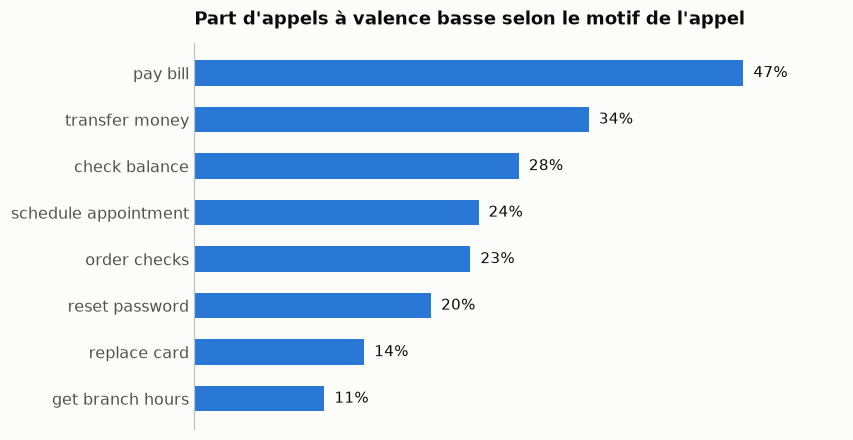

45 clients avec au moins 10 appels ; part d'appels à valence basse : de 0% à 85%, médiane 18%


In [28]:
part_par_motif = appels.groupby("motif").y.mean()
tracer_barres(part_par_motif, "Part d'appels à valence basse selon le motif de l'appel")

par_client = appels.groupby("id_client").y.agg(["mean", "size"])
part_par_client = par_client.loc[par_client["size"] >= 10, "mean"]
print(f"{len(part_par_client)} clients avec au moins 10 appels ; part d'appels à valence basse : "
      f"de {part_par_client.min():.0%} à {part_par_client.max():.0%}, médiane {part_par_client.median():.0%}")

In [29]:
# Vérification 2.3
verifier("huit motifs", lambda: len(part_par_motif) == 8 and proche(part_par_motif.mean(), 0.25, 0.03), "appels.groupby(\"motif\").y.mean()")
verifier("le motif le plus touché dépasse 43 %", lambda: part_par_motif.max() > 43.00 / 100)
verifier("45 clients avec au moins 10 appels", lambda: len(part_par_client) == 45,
         "groupby(\"id_client\").y.agg([\"mean\", \"size\"]) puis filtre sur size >= 10")
verifier("certains clients ne sont jamais étiquetés 1, d'autres presque toujours", lambda: part_par_client.min() < 0.05 and part_par_client.max() > 0.7)

[OK]        huit motifs
[OK]        le motif le plus touché dépasse 43 %
[OK]        45 clients avec au moins 10 appels
[OK]        certains clients ne sont jamais étiquetés 1, d'autres presque toujours


**Réflexion 2.3.** L'étiquette varie beaucoup d'un motif à l'autre, et encore plus d'un client à l'autre. Quel risque cela crée-t-il au moment d'évaluer un modèle ?

**Réponse.** Deux raccourcis s'offrent au modèle.

- **Reconnaître le scénario.** Un modèle qui devine seulement le motif de l'appel fait déjà mieux que le hasard, sans rien savoir de la tonalité. Il faudra mesurer ce repère pour savoir ce que les branches apportent en plus.
- **Reconnaître la personne.** Certains clients sont presque toujours étiquetés 1, d'autres jamais. Si les appels d'un même client se retrouvent à la fois dans l'entraînement et dans le test, le modèle peut apprendre « cette voix, ce vocabulaire = étiquette 1 » et obtenir un bon score qui ne se reproduira pas sur un nouveau client. D'où la partie suivante : on découpe par locuteur.

### Exercice 2.4 : l'étiquette dépend-elle du nom joué par le client ?

La plateforme attribue à chaque appel un nom fictif, que le client donne en se présentant : dix prénoms, dix noms de famille, cent combinaisons. Un nom tiré au sort ne devrait rien dire de la tonalité d'un appel. Vérifie-le.

1. Ajoute à `appels` les colonnes `prenom` et `nom`, en minuscules, tirées de `nom_client` (« Patricia Brown » donne `patricia` et `brown`).
2. Calcule `part_par_nom` : la part d'appels étiquetés 1 pour chaque nom de famille. Trace-la avec `tracer_barres`.
3. Construis `presentations` : les tours du client dont la transcription automatique nettoyée est exactement `hi my name is <prénom> <nom>`, avec le prénom et le nom attribués à cet appel. Le squelette part d'une copie de `tours` : ajoute-lui les colonnes `phrase` (le texte nettoyé), `prenom` et `nom`, sans retirer les autres, puis filtre les lignes.
4. Calcule `grille` : la valence moyenne de ces tours, un prénom par ligne et un nom par colonne (`pivot_table`). Trace-la avec `tracer_grille`.

Indice : `tours.sid.map(appels.prenom)` donne à chaque tour le prénom attribué à son appel.

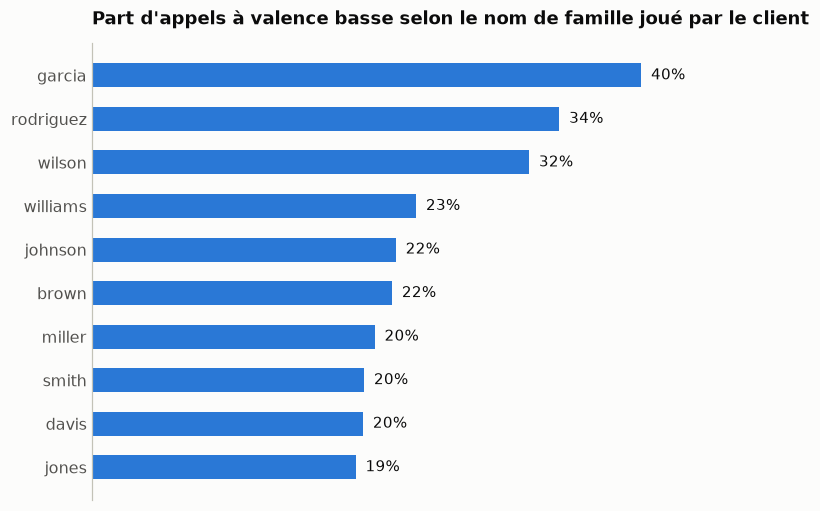

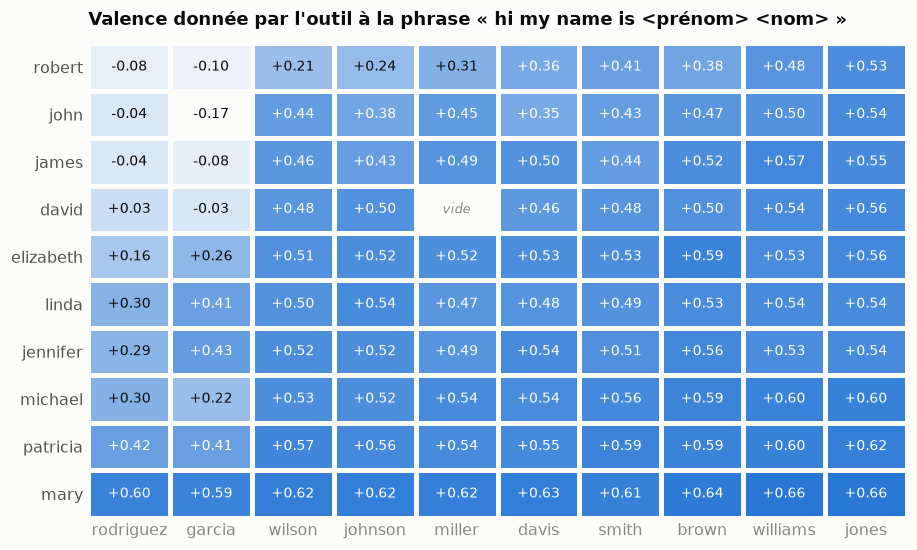

In [30]:
appels["prenom"] = appels.nom_client.str.lower().str.split().str[0]
appels["nom"] = appels.nom_client.str.lower().str.split().str[-1]
part_par_nom = appels.groupby("nom").y.mean()
tracer_barres(part_par_nom, "Part d'appels à valence basse selon le nom de famille joué par le client")

presentations = tours[tours.role == "client"].copy()
presentations["phrase"] = presentations.texte_auto.map(nettoyer)
presentations["prenom"] = presentations.sid.map(appels.prenom)
presentations["nom"] = presentations.sid.map(appels.nom)
presentations = presentations[presentations.phrase == "hi my name is " + presentations.prenom + " " + presentations.nom]
grille = presentations.pivot_table(index="prenom", columns="nom", values="valence", aggfunc="mean")
tracer_grille(grille, "Valence donnée par l'outil à la phrase « hi my name is <prénom> <nom> »")

In [31]:
# Vérification 2.4
verifier("dix prénoms et dix noms, en minuscules", lambda: appels.prenom.nunique() == 10 and appels.nom.nunique() == 10 and appels.nom.str.islower().all(),
         "appels.nom_client.str.lower().str.split().str[0] pour le prénom, .str[-1] pour le nom")
verifier("la part d'étiquettes 1 va du simple au double selon le nom", lambda: len(part_par_nom) == 10 and part_par_nom.max() > 1.8 * part_par_nom.min(),
         "appels.groupby(\"nom\").y.mean()")
verifier("386 présentations retenues", lambda: len(presentations) == 386,
         "presentations.phrase == \"hi my name is \" + presentations.prenom + \" \" + presentations.nom")
verifier("presentations garde les colonnes de tours", lambda: {"sid", "valence", "phrase", "prenom", "nom"} <= set(presentations.columns),
         "ajoute des colonnes à la copie de tours, n'en retire pas : la cellule suivante se sert de sid et de valence")
verifier("une grille de 10 prénoms sur 10 noms", lambda: grille.shape == (10, 10) and grille.index.name == "prenom",
         "presentations.pivot_table(index=\"prenom\", columns=\"nom\", values=\"valence\", aggfunc=\"mean\")")
verifier("la même phrase est jugée positive ou négative selon le nom", lambda: grille.loc["mary", "jones"] > 0.6 and grille.loc["john", "garcia"] < 0)

[OK]        dix prénoms et dix noms, en minuscules
[OK]        la part d'étiquettes 1 va du simple au double selon le nom
[OK]        386 présentations retenues
[OK]        presentations garde les colonnes de tours
[OK]        une grille de 10 prénoms sur 10 noms
[OK]        la même phrase est jugée positive ou négative selon le nom


Avant d'interpréter, deux contrôles fournis. Le premier vérifie que les noms sont bien attribués au hasard : un test du khi-deux d'indépendance donne une valeur p, et une valeur p petite (moins de 0,05) signalerait un lien entre le nom et le motif de l'appel, ou entre le nom et le locuteur. Avec des effectifs aussi dispersés, ce test n'est qu'une indication. Le second contrôle regarde ce que vaut la valence quand exactement la même phrase est prononcée par des personnes différentes, puis dans les tours où le nom n'apparaît pas.

In [32]:
from scipy.stats import chi2_contingency

for colonne in ("prenom", "nom"):
    for autre in ("motif", "id_client"):
        p_valeur = chi2_contingency(pd.crosstab(appels[colonne], appels[autre]))[1]
        print(f"lien entre {colonne:<6} et {autre:<9} : p = {p_valeur:.2f}")

memes = presentations.groupby("phrase").valence.agg(["std", "size"])
print(f"\n{len(presentations)} présentations, {presentations.sid.map(appels.id_client).nunique()} locuteurs, {len(memes)} phrases différentes")
print(f"écart-type de la valence entre les occurrences d'une même phrase : {memes.loc[memes['size'] >= 3, 'std'].median():.3f} (médiane) ; "
      f"sur l'ensemble des présentations : {presentations.valence.std():.3f}")

hispanique = presentations.nom.isin(["garcia", "rodriguez"])
masculin = presentations.prenom.isin(["david", "james", "john", "michael", "robert"])
print(f"valence moyenne de la présentation : {presentations.valence[hispanique].mean():.2f} avec Garcia ou Rodriguez, {presentations.valence[~hispanique].mean():.2f} avec les huit autres noms")
print(f"                                     {presentations.valence[masculin].mean():.2f} avec un prénom masculin, {presentations.valence[~masculin].mean():.2f} avec un prénom féminin")

autres_tours = tours[(tours.role == "client") & tours.parole & ~tours.index.isin(presentations.index)]
sans_le_nom = autres_tours[[nom not in texte.split() and prenom not in texte.split() for texte, prenom, nom in
                            zip(autres_tours.texte_auto.map(nettoyer), autres_tours.sid.map(appels.prenom), autres_tours.sid.map(appels.nom))]]
par_nom = sans_le_nom.valence.groupby(sans_le_nom.sid.map(appels.nom)).mean()
print(f"dans les tours où le nom n'est pas prononcé, la valence moyenne par nom de famille va de {par_nom.min():.2f} à {par_nom.max():.2f}")

lien entre prenom et motif     : p = 0.85
lien entre prenom et id_client : p = 0.10
lien entre nom    et motif     : p = 0.66
lien entre nom    et id_client : p = 0.93

386 présentations, 46 locuteurs, 99 phrases différentes
écart-type de la valence entre les occurrences d'une même phrase : 0.013 (médiane) ; sur l'ensemble des présentations : 0.195
valence moyenne de la présentation : 0.19 avec Garcia ou Rodriguez, 0.52 avec les huit autres noms
                                     0.37 avec un prénom masculin, 0.52 avec un prénom féminin
dans les tours où le nom n'est pas prononcé, la valence moyenne par nom de famille va de 0.04 à 0.06


**Réflexion 2.4.** Que montre la grille ? Les noms étant tirés au sort, d'où vient l'écart ? Qu'est-ce que cela implique pour un champ « sentiment automatique » dans un vrai projet ?

**Réponse.** La même phrase, mot pour mot, reçoit une valence très différente selon le nom qu'elle contient. Avec Garcia ou Rodriguez, les deux noms d'origine hispanique de la liste, la présentation obtient environ 0,19 en moyenne ; avec les huit autres noms, 0,52. Les prénoms masculins tirent aussi vers le bas (0,37 contre 0,52 pour les prénoms féminins, avec des exceptions comme Michael), et les deux effets se cumulent : « hi my name is john garcia » est jugée négative (-0,17), « hi my name is mary jones » très positive (0,66).

Cet écart ne vient ni du contenu des appels, ni des personnes. Les noms sont attribués sans lien décelable avec le motif ou le locuteur. Une même phrase reçoit presque exactement la même valence quel que soit le locuteur (écart-type de 0,01, contre 0,2 sur l'ensemble des présentations) : l'outil réagit aux mots, pas à la voix. Et dès que le nom n'est pas prononcé, la valence ne dépend plus du nom attribué. C'est donc un **biais de l'outil**, porté par le nom lui-même. On ignore d'où il vient, puisque l'outil est une boîte noire. On sait en revanche ce qu'il produit : dans ce corpus, un appel a deux fois plus de chances de recevoir l'étiquette « valence basse » quand le client s'appelle Garcia que lorsqu'il s'appelle Jones (40 % contre 19 %). Wilson dépasse aussi les autres noms dans le graphique en barres sans que la phrase de présentation l'explique : le nom est prononcé dans d'autres tournures, et avec 150 appels par nom une part de hasard reste possible.

Pour un vrai projet, trois conséquences.

1. Un score de sentiment automatique peut dépendre du nom du client, donc indirectement de son genre ou de son origine. C'est un problème d'équité autant que de qualité, et il se transmet à tout modèle entraîné sur ce score.
2. Il faut anonymiser le texte **avant** de le confier à l'outil d'analyse, pas seulement avant d'entraîner son propre modèle. Ici le mal est fait : l'étiquette porte déjà le biais.
3. Ce contrôle se refait sur n'importe quel outil, sans aucune donnée annotée : on lui soumet la même phrase avec des noms différents et on compare les scores.

## Partie 3 : découper par locuteur

On évalue par validation croisée à cinq plis. Chaque appel reçoit un score calculé par un modèle qui ne l'a pas vu : un score **hors pli**. La contrainte importante : **tous les appels d'un même client restent du même côté**, entraînement ou test.

Deux mesures, calculées sur ces scores hors pli :

- **AUC**, pour *area under the curve* : l'aire sous la courbe ROC (*receiver operating characteristic*). Elle se lit comme la probabilité qu'un appel étiqueté 1 pris au hasard reçoive un score plus élevé qu'un appel étiqueté 0 pris au hasard. 0,5 pour le hasard, 1 pour un classement parfait.
- **Précision moyenne** : elle résume la précision obtenue quand on parcourt la liste des appels du score le plus élevé au plus bas. Le hasard donne la proportion d'appels étiquetés 1, ici 0,25.

### Exercice 3.1 : les plis

1. `plis` : liste de cinq couples (positions des appels d'entraînement, positions des appels de test), construits avec `StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)`, les groupes étant les identifiants des clients. La méthode `.split(appels, y, groups=...)` produit les couples un à un : enveloppe-la dans `list(...)`.
2. `plis_hasard` : la même chose avec `StratifiedKFold`, sans groupes. Il ne servira qu'à montrer ce qu'il ne faut pas faire.

Dans ces noms, *Stratified* signifie que chaque pli garde à peu près la même proportion d'étiquettes 1, et *Group* qu'un groupe (ici un client) n'est jamais partagé entre l'entraînement et le test.

In [33]:
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.metrics import roc_auc_score, average_precision_score

plis = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0).split(appels, y, groups=appels.id_client))
plis_hasard = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(appels, y))
for i, (entrainement, test) in enumerate(plis):
    print(f"pli {i} : {len(test)} appels de test, {appels.id_client.iloc[test].nunique()} clients, part d'étiquettes 1 : {y[test].mean():.2f}")

pli 0 : 288 appels de test, 16 clients, part d'étiquettes 1 : 0.24
pli 1 : 273 appels de test, 11 clients, part d'étiquettes 1 : 0.23
pli 2 : 279 appels de test, 10 clients, part d'étiquettes 1 : 0.24
pli 3 : 285 appels de test, 9 clients, part d'étiquettes 1 : 0.28
pli 4 : 321 appels de test, 9 clients, part d'étiquettes 1 : 0.26


In [34]:
# Vérification 3.1
verifier("cinq plis qui couvrent tous les appels une fois", lambda: len(plis) == 5 and sorted(np.concatenate([t for _, t in plis])) == list(range(len(appels))),
         "list(StratifiedGroupKFold(...).split(appels, y, groups=appels.id_client))")
verifier("aucun client des deux côtés d'un pli",
         lambda: all(not set(appels.id_client.iloc[e]) & set(appels.id_client.iloc[t]) for e, t in plis),
         "il faut StratifiedGroupKFold et l'argument groups")
verifier("plis_hasard mélange bien les clients (c'est voulu)",
         lambda: len(plis_hasard) == 5 and any(set(appels.id_client.iloc[e]) & set(appels.id_client.iloc[t]) for e, t in plis_hasard))

[OK]        cinq plis qui couvrent tous les appels une fois
[OK]        aucun client des deux côtés d'un pli
[OK]        plis_hasard mélange bien les clients (c'est voulu)


### Exercice 3.2 : scores hors pli et repère à battre

1. Écris `scores_hors_pli(modele, X, decoupage=None)` : elle renvoie, pour chaque appel, la probabilité de la classe 1 prédite par un modèle entraîné sans cet appel. Par défaut le découpage est `plis`. Indice : `cross_val_predict(..., method="predict_proba")` renvoie deux colonnes.
2. Écris `auc(scores)`.
3. Premier repère : un modèle qui ne connaît que le **motif** de l'appel. Calcule `scores_motif`. scikit-learn attend un tableau à deux dimensions : passe `appels[["motif"]]`, avec deux paires de crochets.

Les lignes de `X` doivent toujours être dans l'ordre de `appels`.

In [35]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

def scores_hors_pli(modele, X, decoupage=None):
    return cross_val_predict(modele, X, y, cv=decoupage if decoupage is not None else plis, method="predict_proba")[:, 1]

def auc(scores):
    return roc_auc_score(y, scores)

def bilan(nom, scores):
    """Affiche les deux mesures pour un jeu de scores hors pli."""
    print(f"{nom:<42} AUC {auc(scores):.3f}   précision moyenne {average_precision_score(y, scores):.3f}")

# Une colonne 0/1 par motif, puis une régression logistique ; class_weight="balanced" donne le même poids total aux deux classes
modele_motif = make_pipeline(OneHotEncoder(handle_unknown="ignore"), LogisticRegression(class_weight="balanced"))
scores_motif = scores_hors_pli(modele_motif, appels[["motif"]])
bilan("Repère : motif de l'appel seul", scores_motif)

Repère : motif de l'appel seul             AUC 0.637   précision moyenne 0.349


In [36]:
# Vérification 3.2
verifier("auc vaut 1 pour un score parfait et 0,5 pour un score constant",
         lambda: proche(auc(-appels.valence_client.values), 1.0, 1e-9) and proche(auc(np.zeros(len(y))), 0.5, 1e-9), "roc_auc_score(y, scores)")
verifier("scores_hors_pli renvoie une probabilité par appel",
         lambda: scores_motif.shape == (len(appels),) and 0 <= scores_motif.min() and scores_motif.max() <= 1,
         "cross_val_predict(modele, X, y, cv=..., method=\"predict_proba\")[:, 1]")
verifier("le motif seul donne une AUC proche de 0,64", lambda: proche(auc(scores_motif), 0.637, 0.03))
verifier("le découpage peut être changé", lambda: scores_hors_pli(modele_motif, appels[["motif"]], plis_hasard).shape == (len(appels),)
         and not np.allclose(scores_hors_pli(modele_motif, appels[["motif"]], plis_hasard), scores_motif),
         "cv=decoupage si decoupage est fourni, sinon cv=plis")

[OK]        auc vaut 1 pour un score parfait et 0,5 pour un score constant
[OK]        scores_hors_pli renvoie une probabilité par appel
[OK]        le motif seul donne une AUC proche de 0,64


[OK]        le découpage peut être changé


**Réflexion 3.2.** Le repère « motif seul » n'est pas à 0,5. Qu'est-ce que cela change dans la lecture des résultats des branches ?

**Réponse.** Le plancher n'est pas 0,5 mais environ 0,64 : c'est ce qu'on obtient en reconnaissant seulement le type d'appel. Une branche qui affiche 0,62 n'a donc rien appris d'utile sur la tonalité, même si elle « bat le hasard ». Chaque résultat se lit par rapport à ce repère, pas par rapport à 0,5.

## Partie 4 : branche A, les mots

La branche A lit ce que dit le client. Dans un vrai projet elle commence par une transcription automatique (tu la referas toi-même avec Whisper en partie 10). Ici le corpus fournit déjà une transcription automatique, `texte_auto`, et une transcription humaine, `texte`, qui sert de référence.

### Exercice 4.1 : que vaut la transcription automatique ?

Le **taux d'erreur de mots** compte les mots à remplacer, supprimer ou insérer pour passer de la transcription automatique à la référence, divisé par le nombre de mots de la référence. `jiwer.wer(references, hypotheses)` le calcule à partir de deux listes de chaînes.

1. Nettoie les deux transcriptions avec `nettoyer`.
2. Ne garde que les tours dont la référence nettoyée n'est pas vide.
3. Calcule `taux_erreur` sur l'ensemble, puis `taux_erreur_client` et `taux_erreur_conseiller`. `jiwer.wer` attend des listes : convertis tes Series avec `.tolist()`.

In [37]:
import jiwer

reference, hypothese = tours.texte.map(nettoyer), tours.texte_auto.map(nettoyer)
garder = reference != ""
taux_erreur = jiwer.wer(reference[garder].tolist(), hypothese[garder].tolist())
taux_erreur_client = jiwer.wer(reference[garder & (tours.role == "client")].tolist(), hypothese[garder & (tours.role == "client")].tolist())
taux_erreur_conseiller = jiwer.wer(reference[garder & (tours.role == "conseiller")].tolist(), hypothese[garder & (tours.role == "conseiller")].tolist())
print(f"taux d'erreur de mots : {taux_erreur:.1%} (client {taux_erreur_client:.1%}, conseiller {taux_erreur_conseiller:.1%}) sur {garder.sum()} tours")

taux d'erreur de mots : 6.5% (client 7.5%, conseiller 5.9%) sur 19301 tours


In [38]:
# Vérification 4.1
verifier("taux d'erreur global proche de 6,5 %", lambda: proche(taux_erreur, 0.0650, 0.004),
         "jiwer.wer(reference[garder].tolist(), hypothese[garder].tolist()), après nettoyer sur les deux")
verifier("le client est moins bien transcrit que le conseiller", lambda: taux_erreur_client > taux_erreur_conseiller and proche(taux_erreur_client, 0.0750, 0.005))

[OK]        taux d'erreur global proche de 6,5 %
[OK]        le client est moins bien transcrit que le conseiller


**Réflexion 4.1.** Pourquoi le client est-il moins bien transcrit que le conseiller ? Et que vaudrait cette mesure si tu avais oublié de retirer les balises des deux transcriptions ?

In [39]:
# Le même calcul sans retirer les balises : [noise] devient le mot « noise » et compte comme une erreur
sans_ponctuation = lambda texte: re.sub(r"\s+", " ", re.sub(r"[^a-z' ]", " ", texte.lower())).strip()
ref_brute, hyp_brute = tours.texte.map(sans_ponctuation), tours.texte_auto.map(sans_ponctuation)
print(f"avec les balises comptées comme des mots : {jiwer.wer(ref_brute[ref_brute != ''].tolist(), hyp_brute[ref_brute != ''].tolist()):.1%}")

avec les balises comptées comme des mots : 8.9%


**Réponse.** Explication probable : le conseiller suit un script et répète les mêmes phrases d'un appel à l'autre, alors que le client dicte des noms, des adresses et des numéros et parle de façon plus spontanée. Ce sont les mots les plus difficiles pour un système de transcription.

Sans retirer les balises, le taux affiché monte à près de 9 % au lieu de 6,5 % : les deux transcriptions ne notent pas les bruits de la même façon, et chaque désaccord sur un `[noise]` compte comme une erreur de mot. Un taux d'erreur n'a de sens qu'accompagné de sa règle de nettoyage.

Enfin, ce taux est bas parce que ces appels sont courts, scriptés et en anglais. Sur de vrais appels français de centre de contact, la seule mesure trouvée pendant la préparation de ce TP donne 22 à 43 % pour Whisper large-v3 (tests privés de l'auteur d'un modèle, non vérifiables).

### Exercice 4.2 : le texte du client, appel par appel

Construis `texte_client` : une Series indexée comme `appels`, qui contient pour chaque appel les transcriptions automatiques nettoyées des tours du client (avec parole), mises bout à bout dans l'ordre.

In [40]:
tours_client = tours[(tours.role == "client") & tours.parole]
texte_client = tours_client.texte_auto.map(nettoyer).groupby(tours_client.sid).agg(" ".join).reindex(appels.index).fillna("")
print(texte_client.iloc[0])

hi my name is patricia brown i lost my debit card can you send me a new one my debit card yes my debit card no that was going to be at hi


In [41]:
# Vérification 4.2
verifier("un texte par appel, dans l'ordre de appels", lambda: list(texte_client.index) == list(appels.index), ".reindex(appels.index)")
verifier("aucun texte vide, aucune balise", lambda: (texte_client.str.len() > 0).all() and not texte_client.str.contains(r"[\[\]<>]").any(),
         "applique nettoyer à texte_auto avant de regrouper")
verifier("environ 37 mots par appel", lambda: proche(texte_client.str.split().str.len().mean(), 36.88, 1.0),
         "seulement les tours du client avec parole, joints par \" \".join")

[OK]        un texte par appel, dans l'ordre de appels
[OK]        aucun texte vide, aucune balise
[OK]        environ 37 mots par appel


### Exercice 4.3 : un premier classifieur de texte

Le modèle le plus simple qui marche : chaque appel devient un vecteur **TF-IDF** (*term frequency, inverse document frequency* : une coordonnée par mot ou paire de mots, d'autant plus forte que le mot revient dans l'appel et qu'il est rare dans les autres), puis une **régression logistique** apprend un poids par coordonnée.

1. Écris `modele_texte()`, qui renvoie un pipeline scikit-learn neuf :
   `TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)` suivi de `LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced")`.
   Lecture des réglages : mots seuls et paires de mots (`ngram_range`), présents dans au moins deux appels (`min_df`), une répétition comptant moins que la première occurrence (`sublinear_tf`) ; `C` règle la régularisation (plus il est petit, plus les poids sont tirés vers zéro).
2. Calcule `scores_A_brut`, les scores hors pli sur `texte_client`.

In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

def modele_texte():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                         LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"))

scores_A_brut = scores_hors_pli(modele_texte(), texte_client)
bilan("Repère : motif de l'appel seul", scores_motif)
bilan("A, transcription automatique brute", scores_A_brut)

Repère : motif de l'appel seul             AUC 0.637   précision moyenne 0.349
A, transcription automatique brute         AUC 0.862   précision moyenne 0.676


In [43]:
# Vérification 4.3
verifier("modele_texte renvoie un pipeline neuf à chaque appel", lambda: modele_texte() is not modele_texte() and hasattr(modele_texte(), "predict_proba"),
         "make_pipeline(TfidfVectorizer(...), LogisticRegression(...))")
verifier("AUC proche de 0,86", lambda: proche(auc(scores_A_brut), 0.862, 0.03))
verifier("nettement au-dessus du repère « motif seul »", lambda: auc(scores_A_brut) > auc(scores_motif) + 0.1)

[OK]        modele_texte renvoie un pipeline neuf à chaque appel
[OK]        AUC proche de 0,86
[OK]        nettement au-dessus du repère « motif seul »


Un bon score ne dit pas *pourquoi* le modèle réussit. L'outil suivant entraîne le modèle sur tous les appels et affiche les mots qui pèsent le plus dans chaque sens.

In [44]:
def mots_marquants(textes, n=14):
    """Les n mots (ou paires de mots) qui tirent le plus vers l'étiquette 1 (valence basse) et vers l'étiquette 0."""
    modele = modele_texte().fit(textes, y)
    mots, poids = np.array(modele[0].get_feature_names_out()), modele[1].coef_[0]
    ordre = np.argsort(poids)
    return pd.DataFrame({"vers valence basse": mots[ordre[-n:]][::-1], "vers valence haute": mots[ordre[:n]]})

mots_marquants(texte_client)

,vers valence basse,vers valence haute
0,rodriguez,thank you
1,robert,thank
2,is robert,you
3,all you,bye
4,see,it thank
5,garcia,no thank
6,it you,for today
7,mm,today
8,one,much
9,hmm,too bye


**Réflexion 4.3.** Dans la colonne « vers valence basse », vois-tu des mots qui ne devraient avoir aucun rapport avec la tonalité d'un appel ? Pourquoi le modèle s'en sert-il quand même ?

**Réponse.** Oui : des noms propres (`robert`, `rodriguez`, `garcia`) et des fragments d'adresse ou de numéro (`address is`, `one`). Ils n'ont rien à voir avec l'humeur du client.

Le modèle s'en sert parce que l'étiquette elle-même dépend de ces mots. On a vu en 2.4 que l'outil donne une valence plus basse aux phrases qui contiennent certains noms (Rodriguez, Garcia, Robert), et en 2.2 qu'il juge « négatifs » les tours où le client dicte une adresse ou un numéro. Le classifieur a donc appris les défauts de l'outil. C'est l'intérêt de regarder les poids : ils montrent ce que l'étiquette récompense vraiment. Dans un vrai projet, ces mots sont en plus des données personnelles, qu'il faut retirer avant tout traitement.

### Exercice 4.4 : anonymiser

On masque deux choses dans le texte : les noms joués pendant l'appel (connus par la fiche de l'appel) et les nombres dictés en toutes lettres.

Écris `anonymiser(texte, noms)` :

1. chaque mot de chaque nom de la liste `noms` (en minuscules) est remplacé par `[nom]` ;
2. chaque nombre écrit en lettres est remplacé par `[num]` : l'expression régulière `motif_nombres`, fournie, reconnaît les mots de la liste `NOMBRES` ;
3. plusieurs `[num]` qui se suivent sont réduits à un seul.

Puis construis `texte_anonyme` (même index que `appels`) : pour chaque appel `sid`, applique la fonction à `texte_client[sid]` avec la liste `[appels.nom_client[sid], appels.nom_conseiller[sid]]`. Une compréhension de dictionnaire sur `appels.index`, passée à `pd.Series`, fait l'affaire. Calcule enfin `scores_A`.

Indice : `\b` désigne une limite de mot dans une expression régulière, et `re.escape(mot)` protège les caractères spéciaux.

In [45]:
NOMBRES = ("zero one two three four five six seven eight nine ten eleven twelve thirteen fourteen fifteen sixteen "
           "seventeen eighteen nineteen twenty thirty forty fifty sixty seventy eighty ninety hundred thousand").split()
motif_nombres = re.compile(r"\b(?:" + "|".join(NOMBRES) + r")\b")       # un nombre en lettres, mot entier
motif_nombres.findall("i have one card and someone took twenty five dollars")

['one', 'twenty', 'five']

In [46]:
def anonymiser(texte, noms=()):
    for nom in noms:
        for mot in str(nom).lower().split():
            texte = re.sub(rf"\b{re.escape(mot)}\b", "[nom]", texte)
    texte = motif_nombres.sub("[num]", texte)
    return re.sub(r"(?:\[num\]\s*)+", "[num] ", texte).strip()

texte_anonyme = pd.Series({sid: anonymiser(texte_client[sid], [appels.nom_client[sid], appels.nom_conseiller[sid]])
                           for sid in appels.index})
print(texte_anonyme.iloc[0])
scores_A = scores_hors_pli(modele_texte(), texte_anonyme)
bilan("A, transcription automatique brute", scores_A_brut)
bilan("A, transcription automatique anonymisée", scores_A)
mots_marquants(texte_anonyme)

hi my name is [nom] [nom] i lost my debit card can you send me a new [num] my debit card yes my debit card no that was going to be at hi


A, transcription automatique brute         AUC 0.862   précision moyenne 0.676
A, transcription automatique anonymisée    AUC 0.849   précision moyenne 0.665


,vers valence basse,vers valence haute
0,all you,thank you
1,see,thank
2,it you,you
3,mm,bye
4,address is,it thank
5,address,no thank
6,hmm,for today
7,gonna be,today
8,are the,too bye
9,gas,much


In [47]:
# Vérification 4.4
verifier("noms et nombres masqués",
         lambda: anonymiser("my name is patricia brown i live at nine twenty five main street", ["Patricia Brown", "Linda"])
                 == "my name is [nom] [nom] i live at [num] main street",
         "noms en minuscules mot par mot, puis motif_nombres.sub(\"[num]\", texte), puis fusion des [num] consécutifs et .strip()")
verifier("un mot qui contient un nombre n'est pas touché", lambda: anonymiser("someone is on the phone") == "someone is on the phone",
         "entoure chaque mot de \\b dans l'expression régulière")
verifier("texte_anonyme aligné sur appels", lambda: list(texte_anonyme.index) == list(appels.index),
         "pd.Series({sid: anonymiser(texte_client[sid], [...]) for sid in appels.index})")
verifier("les noms sont masqués dans la plupart des appels", lambda: texte_anonyme.str.contains(r"\[nom\]").mean() > 0.8,
         "passe à anonymiser la liste [appels.nom_client[sid], appels.nom_conseiller[sid]] de chaque appel")
verifier("scores_A est calculé sur le texte anonymisé", lambda: not np.allclose(scores_A, scores_A_brut), "scores_hors_pli(modele_texte(), texte_anonyme)")
verifier("AUC proche de 0,85", lambda: proche(auc(scores_A), 0.849, 0.03))

[OK]        noms et nombres masqués
[OK]        un mot qui contient un nombre n'est pas touché
[OK]        texte_anonyme aligné sur appels
[OK]        les noms sont masqués dans la plupart des appels
[OK]        scores_A est calculé sur le texte anonymisé
[OK]        AUC proche de 0,85


**Réflexion 4.4.** Le score a-t-il beaucoup changé ? Les mots marquants sont-ils plus crédibles ? Trouve dans `texte_anonyme` un effet indésirable du masquage des nombres.

**Réponse.** Le score baisse d'environ un point : le modèle ne peut plus reproduire la part de l'étiquette qui tient aux noms et aux nombres. C'est tant mieux : cette part est un défaut de l'outil, pas une information sur l'appel, et on ne veut pas l'apprendre. Les mots marquants sont maintenant lisibles : remerciements et formules de fin d'un côté, hésitations et échanges d'informations de l'autre.

Effet indésirable : `one` est aussi un pronom. « can you send me a new one » devient « a new [num] ». Un masquage par liste de mots masque trop. Les outils sérieux (Presidio, par exemple) combinent listes, reconnaissance d'entités et contexte, et il faut quand même contrôler leur sortie sur un échantillon.

### Exercice 4.5 : transcription humaine ou automatique ?

Refais exactement la même chaîne avec la transcription humaine (`texte`), sur les mêmes tours (ceux du client avec parole) : nettoyage, regroupement par appel, anonymisation, scores hors pli. Range le texte dans `texte_humain` et le résultat dans `scores_A_humain`.

In [48]:
texte_humain = tours_client.texte.map(nettoyer).groupby(tours_client.sid).agg(" ".join).reindex(appels.index).fillna("")
texte_humain = pd.Series({sid: anonymiser(texte_humain[sid], [appels.nom_client[sid], appels.nom_conseiller[sid]]) for sid in appels.index})
scores_A_humain = scores_hors_pli(modele_texte(), texte_humain)
bilan("A, transcription automatique anonymisée", scores_A)
bilan("A, transcription humaine anonymisée", scores_A_humain)

A, transcription automatique anonymisée    AUC 0.849   précision moyenne 0.665
A, transcription humaine anonymisée        AUC 0.820   précision moyenne 0.647


In [49]:
# Vérification 4.5
verifier("scores calculés sur la transcription humaine", lambda: scores_A_humain.shape == (len(appels),) and not np.allclose(scores_A_humain, scores_A))
verifier("la transcription humaine est anonymisée elle aussi", lambda: texte_humain.str.contains(r"\[nom\]").mean() > 0.8,
         "applique anonymiser à chaque appel, comme en 4.4")
verifier("AUC proche de 0,82", lambda: proche(auc(scores_A_humain), 0.820, 0.03),
         "même chaîne que 4.2 et 4.4, en partant de la colonne texte")

[OK]        scores calculés sur la transcription humaine
[OK]        la transcription humaine est anonymisée elle aussi
[OK]        AUC proche de 0,82


**Réflexion 4.5.** La transcription humaine est la plus fidèle, et pourtant elle donne un score plus bas. Propose une explication, puis une mesure qui permettrait de la vérifier.

In [50]:
# L'outil a-t-il lu la transcription automatique ? On regarde les tours du client où une seule des deux transcriptions contient un remerciement.
merci = pd.DataFrame({"automatique": tours_client.texte_auto.str.contains(r"\bthank"), "humaine": tours_client.texte.str.contains(r"\bthank"),
                      "valence": tours_client.valence})
merci.groupby(["automatique", "humaine"]).valence.agg(valence_moyenne="mean", tours="size").round(2)

valence_moyenne  tours
automatique humaine                        
False       False               0.04   9367
            True               -0.06     24
True        False               0.55     27
            True                0.57   1228

**Réponse.** Explication : l'outil qui a produit l'étiquette a lu **sa propre transcription automatique**, erreurs comprises. Un classifieur qui lit le même texte que lui retrouve plus facilement ses décisions. La transcription humaine est meilleure, mais ce n'est pas elle que l'outil a vue.

La documentation du corpus ne décrit pas le fonctionnement de l'outil, mais le tableau ci-dessus le montre. Quand seule la transcription automatique contient « thank », la valence moyenne est aussi haute que quand les deux le contiennent. Quand seule la transcription humaine le contient, la valence est aussi basse que quand aucune ne le contient. La valence suit donc ce qu'a écrit la transcription automatique, pas ce qui a été réellement dit. Les effectifs des deux cas de désaccord sont petits (quelques dizaines de tours), mais l'écart est massif.

Leçon générale : une étiquette automatique porte la marque de l'outil qui l'a fabriquée. Avec une étiquette posée par des humains qui écoutent l'appel, on s'attendrait à l'inverse : la meilleure transcription donnerait le meilleur score.

Pour la suite, la branche A est `scores_A` : transcription automatique, nettoyée, anonymisée. C'est la chaîne qu'on aurait en production.

## Partie 5 : branche B, la voix

La branche B ignore les mots et ne regarde que la façon de parler : hauteur de la voix, intensité, timbre, régularité. On utilise **eGeMAPS** (*extended Geneva Minimalistic Acoustic Parameter Set*), un jeu standard de 88 descripteurs acoustiques conçu pour l'analyse de la voix et des émotions, calculé par la bibliothèque openSMILE. Pour chaque tour de parole, on obtient 88 nombres.

### Exercice 5.1 : extraire le signal d'un tour

Écris `signal_du_tour(tour)`. `tour` est une ligne de `tours` : tu disposes de `tour.sid`, `tour.canal`, `tour.position_s`, `tour.duree_s`.

1. Trouve le fichier avec `fichier_audio`.
2. Lis seulement le morceau utile : `sf.read(chemin, start=..., frames=..., dtype="float32")`. `start` et `frames` se comptent en échantillons : multiplie les secondes par la fréquence d'échantillonnage du fichier (`sf.info(chemin).samplerate`, ici 8 000).
3. Rééchantillonne à 16 000 Hz, la fréquence attendue par la plupart des modèles de parole : `resample_poly(signal, 16000, frequence_du_fichier)`.
4. Renvoie un tableau `float32`.

In [51]:
def signal_du_tour(tour, frequence_cible=16000):
    chemin = str(fichier_audio(tour.sid, tour.canal))
    frequence = sf.info(chemin).samplerate
    signal, _ = sf.read(chemin, start=int(tour.position_s * frequence), frames=int(tour.duree_s * frequence), dtype="float32")
    return resample_poly(signal, frequence_cible, frequence).astype(np.float32)

tour_test = tours[(tours.role == "client") & tours.parole & (tours.duree_s >= 2)].iloc[0]
signal_test = signal_du_tour(tour_test)
print(f"« {tour_test.texte} » : {tour_test.duree_s:.2f} s, {len(signal_test)} échantillons")
Audio(signal_test, rate=16000)

« hi my name is elizabeth david i need to check my account balance » : 4.08 s, 65280 échantillons


In [52]:
# Vérification 5.1
verifier("tableau float32 à une dimension", lambda: signal_test.dtype == np.float32 and signal_test.ndim == 1)
verifier("la durée du signal correspond à celle du tour, à 16 000 Hz", lambda: proche(len(signal_test) / 16000, tour_test.duree_s, 0.01),
         "start et frames en échantillons du fichier (secondes x 8000), puis resample_poly(signal, 16000, 8000)")
verifier("le signal n'est pas du silence", lambda: float(np.abs(signal_test).max()) > 0.01,
         "vérifie que tu lis le bon fichier (fichier_audio avec tour.canal) à la bonne position (tour.position_s)")

# Le cas piège : un tour du client dans un appel inversé, sur le canal 2, là où les deux horloges diffèrent
def lecture_de_reference(tour):
    chemin = DONNEES / "audio" / ("caller" if tour.canal == 1 else "agent") / f"{tour.sid}.wav"
    frequence = sf.info(str(chemin)).samplerate
    brut, _ = sf.read(str(chemin), start=int(tour.start_s * frequence), frames=int(tour.duree_s * frequence), dtype="float32")
    return resample_poly(brut, 16000, frequence)

def meme_signal(tour):
    obtenu, attendu = signal_du_tour(tour), lecture_de_reference(tour)
    n = min(len(obtenu), len(attendu))
    return abs(len(obtenu) - len(attendu)) <= 32 and np.corrcoef(obtenu[:n], attendu[:n])[0, 1] > 0.9

def tour_piege():
    return tours[tours.sid.isin(appels.index[appels.canal_client != 1]) & (tours.role == "client") & tours.parole
                 & (tours.duree_s >= 2) & (tours.ecart_s > 0.5)].iloc[0]

verifier("un tour du client d'un appel inversé est lu dans le bon fichier, à la bonne position", lambda: meme_signal(tour_piege()),
         "le fichier se choisit par le canal (exercice 1.4) et la position est position_s, pas debut_s (exercice 1.3)")

[OK]        tableau float32 à une dimension
[OK]        la durée du signal correspond à celle du tour, à 16 000 Hz
[OK]        le signal n'est pas du silence
[OK]        un tour du client d'un appel inversé est lu dans le bon fichier, à la bonne position


### Exercice 5.2 : 88 descripteurs pour un signal

L'extracteur est créé ci-dessous. Écris `descripteurs(signal)`, qui renvoie une Series de 88 valeurs. `extracteur.process_signal(signal, 16000)` renvoie un tableau d'une seule ligne.

In [53]:
import opensmile
extracteur = opensmile.Smile(feature_set=opensmile.FeatureSet.eGeMAPSv02,
                             feature_level=opensmile.FeatureLevel.Functionals)

In [54]:
def descripteurs(signal):
    return extracteur.process_signal(signal, 16000).iloc[0]

d = descripteurs(signal_test)
print(len(d), "descripteurs, par exemple :")
d[["F0semitoneFrom27.5Hz_sma3nz_amean", "loudness_sma3_amean", "jitterLocal_sma3nz_amean", "MeanVoicedSegmentLengthSec"]].rename("valeur")

88 descripteurs, par exemple :


F0semitoneFrom27.5Hz_sma3nz_amean    36.324314
loudness_sma3_amean                   0.300589
jitterLocal_sma3nz_amean              0.024065
MeanVoicedSegmentLengthSec            0.257000
Name: valeur, dtype: float32

In [55]:
# Vérification 5.2
verifier("une Series de 88 valeurs", lambda: isinstance(descripteurs(signal_test), pd.Series) and len(descripteurs(signal_test)) == 88,
         "extracteur.process_signal(signal, 16000).iloc[0]")
verifier("valeurs numériques finies", lambda: np.isfinite(descripteurs(signal_test).values.astype(float)).all())

[OK]        une Series de 88 valeurs


[OK]        valeurs numériques finies


### Tous les tours du client

La cellule suivante applique tes deux fonctions à tous les tours du client qui contiennent de la parole et durent au moins 0,4 seconde, en parallèle. C'est le calcul le plus long du TP : environ cinq minutes, durée mesurée sur une machine à deux cœurs lors de la préparation. Le résultat est rangé dans un fichier : si tu relances la cellule, elle le relit au lieu de recalculer. Ce fichier dépend de tout ce qui précède : si tu modifies `signal_du_tour`, `descripteurs`, `fichier_audio`, ou les colonnes `position_s` et `parole`, supprime-le (`fichier_cache.unlink()`) avant de relancer.

In [56]:
from joblib import Parallel, delayed

a_traiter = tours[(tours.role == "client") & tours.parole & (tours.duree_s >= 0.4)]
fichier_cache = CACHE / "acoustique_tours.pkl"

def traiter_appel(groupe):
    lignes = []
    for tour in groupe.itertuples():
        signal = signal_du_tour(tour)
        if len(signal) >= 0.3 * 16000:                       # garde-fou : un signal trop court ne se décrit pas
            lignes.append(descripteurs(signal).rename((tour.sid, tour.rang)))
    return lignes

if fichier_cache.exists():
    acoustique = pd.read_pickle(fichier_cache)
    print("relu depuis", fichier_cache.name)
else:
    debut, blocs = time.time(), []
    groupes = [g for _, g in a_traiter.groupby("sid")]
    for depart in range(0, len(groupes), 200):                # par paquets de 200 appels, pour afficher l'avancement
        blocs += Parallel(n_jobs=os.cpu_count(), prefer="threads")(delayed(traiter_appel)(g) for g in groupes[depart:depart + 200])
        print(f"  {min(depart + 200, len(groupes))} appels sur {len(groupes)}, {time.time() - debut:.0f} s écoulées")
    acoustique = pd.DataFrame([ligne for bloc in blocs for ligne in bloc])
    acoustique.index = pd.MultiIndex.from_tuples(acoustique.index, names=["sid", "rang"])
    acoustique.to_pickle(fichier_cache)
    print(f"calculé en {time.time() - debut:.0f} s")
print(acoustique.shape[0], "tours x", acoustique.shape[1], "descripteurs")

  200 appels sur 1446, 39 s écoulées


  400 appels sur 1446, 77 s écoulées


  600 appels sur 1446, 114 s écoulées


  800 appels sur 1446, 156 s écoulées


  1000 appels sur 1446, 194 s écoulées


  1200 appels sur 1446, 234 s écoulées


  1400 appels sur 1446, 272 s écoulées


  1446 appels sur 1446, 281 s écoulées


calculé en 282 s
9177 tours x 88 descripteurs


### Exercice 5.3 : un vecteur par appel

Le modèle a besoin d'une ligne par appel, pas par tour. Résume chaque descripteur par sa **moyenne**, son **écart-type** et son **maximum** sur les tours de l'appel. Construis `X_B` : une ligne par appel dans l'ordre de `appels`, 264 colonnes nommées `descripteur__mean`, `descripteur__std`, `descripteur__max`.

Indice : `acoustique.groupby(level="sid").agg(["mean", "std", "max"])` produit des colonnes à deux niveaux, c'est-à-dire des couples `(descripteur, statistique)`. Aplatis-les en chaînes de caractères avec une compréhension de liste sur `.columns`.

In [57]:
agregat = acoustique.groupby(level="sid").agg(["mean", "std", "max"])
agregat.columns = [f"{nom}__{statistique}" for nom, statistique in agregat.columns]
X_B = agregat.reindex(appels.index)
print(X_B.shape)

(1446, 264)


In [58]:
# Vérification 5.3
verifier("1 446 lignes dans l'ordre de appels, 264 colonnes", lambda: X_B.shape == (1446, 264) and list(X_B.index) == list(appels.index),
         ".reindex(appels.index) après l'agrégation")
verifier("colonnes nommées descripteur__statistique", lambda: {c.split("__")[-1] for c in X_B.columns} == {"mean", "std", "max"},
         "agregat.columns = [f\"{nom}__{statistique}\" for nom, statistique in agregat.columns]")
verifier("chaque appel a des valeurs", lambda: X_B.filter(like="__mean").shape[1] == 88 and X_B.filter(like="__mean").notna().all(axis=1).all())

[OK]        1 446 lignes dans l'ordre de appels, 264 colonnes
[OK]        colonnes nommées descripteur__statistique
[OK]        chaque appel a des valeurs


### Exercice 5.4 : le classifieur de la voix, évalué de deux façons

Pour des tableaux de nombres, on utilise des arbres de décision boostés (`modele_tableau`, fourni). Ils acceptent les valeurs manquantes et ne demandent aucune normalisation.

1. Calcule `scores_B` avec le découpage par locuteur (`plis`).
2. Calcule `scores_B_hasard` avec le découpage au hasard (`plis_hasard`).

In [59]:
from sklearn.ensemble import HistGradientBoostingClassifier

def modele_tableau():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=300, random_state=0)

In [60]:
scores_B = scores_hors_pli(modele_tableau(), X_B)
scores_B_hasard = scores_hors_pli(modele_tableau(), X_B, plis_hasard)
bilan("Repère : motif de l'appel seul", scores_motif)
bilan("B, découpage par locuteur", scores_B)
bilan("B, découpage au hasard", scores_B_hasard)

Repère : motif de l'appel seul             AUC 0.637   précision moyenne 0.349
B, découpage par locuteur                  AUC 0.526   précision moyenne 0.277
B, découpage au hasard                     AUC 0.700   précision moyenne 0.495


In [61]:
# Vérification 5.4
verifier("par locuteur, la voix reste proche du hasard", lambda: 0.40 <= auc(scores_B) <= 0.63, "scores_hors_pli(modele_tableau(), X_B)")
verifier("au hasard, le score paraît bien meilleur", lambda: auc(scores_B_hasard) > auc(scores_B) + 0.07,
         "scores_hors_pli(modele_tableau(), X_B, plis_hasard)")

[OK]        par locuteur, la voix reste proche du hasard
[OK]        au hasard, le score paraît bien meilleur


**Réflexion 5.4.** Les mêmes données et le même modèle donnent deux scores très différents selon le découpage. Lequel faut-il croire, et d'où vient l'écart ? Propose une expérience pour le prouver avant de lire la suite.

**Réponse.** Il faut croire le découpage par locuteur : c'est lui qui répond à la question « que se passera-t-il avec un client que le modèle n'a jamais entendu ? ». Réponse : rien d'utile, la voix seule reste au niveau du hasard, en dessous même du repère « motif seul ».

Avec le découpage au hasard, les appels d'un même client sont des deux côtés. Les descripteurs acoustiques caractérisent très bien une voix. Le modèle apprend donc « cette voix est souvent étiquetée 1 » et retrouve la même voix dans le test. Il reconnaît des personnes, pas une tonalité. L'expérience qui le prouve est l'exercice suivant : si ces descripteurs savent identifier le locuteur, l'explication tient.

### Exercice 5.5 : la preuve par l'identification du locuteur

Entraîne `modele_tableau()` à reconnaître **qui parle** à partir des descripteurs moyens de l'appel (colonnes `__mean` de `X_B`), parmi les dix clients les plus fréquents. Mesure son exactitude par validation croisée ordinaire à cinq plis : `exactitude_locuteur`.

Indice : `cross_val_score(modele, X, cible, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()`. Le hasard donnerait environ 10 %.

In [62]:
frequents = appels.id_client.value_counts().head(10).index
masque = appels.id_client.isin(frequents).values
X_moyennes = X_B.loc[masque, [c for c in X_B.columns if c.endswith("__mean")]]
exactitude_locuteur = cross_val_score(modele_tableau(), X_moyennes, appels.id_client[masque],
                                      cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
print(f"locuteur reconnu dans {exactitude_locuteur:.0%} des {masque.sum()} appels (hasard : environ 10 %)")

locuteur reconnu dans 97% des 706 appels (hasard : environ 10 %)


In [63]:
# Vérification 5.5
verifier("88 descripteurs moyens pour les appels des dix clients", lambda: X_moyennes.shape == (int(masque.sum()), 88),
         "X_B.loc[masque, [c for c in X_B.columns if c.endswith(\"__mean\")]]")
verifier("les descripteurs reconnaissent le locuteur dans plus de 85 % des cas", lambda: exactitude_locuteur > 0.85,
         "cross_val_score(modele_tableau(), X_moyennes, appels.id_client[masque], cv=...) ; les variables sont les colonnes __mean de X_B.loc[masque]")

[OK]        88 descripteurs moyens pour les appels des dix clients
[OK]        les descripteurs reconnaissent le locuteur dans plus de 85 % des cas


**Réflexion 5.5.** Que retiens-tu pour un projet réel où l'on voudrait évaluer une branche « voix » ?

**Réponse.** Trois choses.

1. Les descripteurs de voix identifient presque parfaitement la personne. Toute évaluation qui laisse la même voix dans l'entraînement et dans le test mesure de la reconnaissance du locuteur. En centre de contact, il faut découper par client, et aussi par conseiller si sa voix est analysée. Dans ce corpus, 54 des 59 locuteurs jouent tantôt le client, tantôt le conseiller. Nos plis ne regroupent que par client : cela suffit pour les branches A et B, qui ne lisent que le côté client, mais la branche C voit aussi le comportement du conseiller.
2. Un bon score ne suffit pas : il faut se demander par quel raccourci le modèle a pu l'obtenir, puis fermer ce raccourci.
3. Ici, une fois le raccourci fermé, la voix n'apporte rien. Ce n'est pas une loi générale : l'étiquette de ce TP vient d'un outil qui semble lire surtout les mots. Avec une étiquette posée par des personnes qui écoutent l'appel, la voix peut compter davantage. La partie 10 teste aussi un encodeur de voix plus puissant.

## Partie 6 : branche C, le déroulement

La branche C ne s'intéresse ni au sens des mots ni au timbre de la voix. Elle regarde la **forme** de la conversation : qui parle combien de temps, qui coupe qui, combien de silences. Ces indicateurs ne coûtent presque rien : il suffit de l'horodatage des tours, et du nombre de mots pour le débit.

On ne garde que les tours avec parole. Les tours sont triés par `debut_s`. Entre deux tours consécutifs, l'**écart** est le début du second moins la fin du premier : positif pour un silence, négatif pour un chevauchement. Il y a **alternance** quand les deux tours ne sont pas dits par la même personne.

| indicateur | définition |
|---|---|
| `n_tours_client`, `n_tours_conseiller` | nombre de tours de chacun |
| `parole_client_s`, `parole_conseiller_s` | somme des durées des tours de chacun |
| `part_client` | parole du client divisée par la parole totale |
| `duree_max_client_s` | durée du plus long tour du client |
| `debit_client` | nombre de mots du client (transcription automatique nettoyée) divisé par `parole_client_s` |
| `alternances` | nombre d'alternances |
| `n_chevauchements`, `chevauchement_s` | nombre d'alternances à écart négatif, et somme de leurs durées (en valeur positive) |
| `latence_conseiller_s` | écart moyen, parmi les écarts positifs, quand le conseiller prend la parole après le client (0 s'il n'y en a pas) |
| `latence_client_s` | la même chose quand le client prend la parole après le conseiller |
| `silence_max_s` | plus grand écart positif entre deux tours consécutifs (0 s'il n'y en a pas) |
| `silence_total_s` | somme des écarts positifs entre tours consécutifs |

### Exercice 6.1 : les indicateurs d'un appel

Complète `indicateurs(t)`. Un petit appel inventé, `exemple`, sert de test : calcule d'abord ses indicateurs à la main. Il contient les deux cas délicats : le client parle deux fois de suite (un silence, mais pas une alternance), et le conseiller coupe le client (un chevauchement).

In [64]:
exemple = pd.DataFrame({
    "role":       ["conseiller", "client", "client", "conseiller", "client", "conseiller"],
    "debut_s":    [0.0, 2.5, 7.0, 8.5, 10.5, 12.0],
    "duree_s":    [2.0, 3.0, 2.0, 1.0, 1.0, 1.0],
    "texte_auto": ["hello how can i help you", "hi i lost my card", "it was in my wallet", "okay", "thank you", "you're welcome"],
})
exemple

,role,debut_s,duree_s,texte_auto
0,conseiller,0.0,2.0,hello how can i help you
1,client,2.5,3.0,hi i lost my card
2,client,7.0,2.0,it was in my wallet
3,conseiller,8.5,1.0,okay
4,client,10.5,1.0,thank you
5,conseiller,12.0,1.0,you're welcome


In [65]:
def indicateurs(t):
    """t : les tours (avec parole) d'un seul appel. Renvoie un dictionnaire d'indicateurs."""
    t = t.sort_values("debut_s")
    client, conseiller = t[t.role == "client"], t[t.role == "conseiller"]
    debut, role = t.debut_s.values, t.role.values
    fin = debut + t.duree_s.values
    ecarts = debut[1:] - fin[:-1]
    change = role[1:] != role[:-1]
    vers_client = change & (role[1:] == "client")
    vers_conseiller = change & (role[1:] == "conseiller")
    moyenne = lambda v: float(v.mean()) if len(v) else 0.0
    parole_client, parole_conseiller = float(client.duree_s.sum()), float(conseiller.duree_s.sum())
    mots_client = int(client.texte_auto.map(nettoyer).str.split().str.len().sum())
    return {
        "n_tours_client": len(client),
        "n_tours_conseiller": len(conseiller),
        "parole_client_s": parole_client,
        "parole_conseiller_s": parole_conseiller,
        "part_client": parole_client / max(parole_client + parole_conseiller, 1e-9),
        "duree_max_client_s": float(client.duree_s.max()) if len(client) else 0.0,
        "debit_client": mots_client / max(parole_client, 1e-9),
        "alternances": int(change.sum()),
        "n_chevauchements": int((change & (ecarts < 0)).sum()),
        "chevauchement_s": float(np.abs(ecarts[change & (ecarts < 0)]).sum()),
        "latence_conseiller_s": moyenne(ecarts[vers_conseiller & (ecarts > 0)]),
        "latence_client_s": moyenne(ecarts[vers_client & (ecarts > 0)]),
        "silence_max_s": float(ecarts[ecarts > 0].max()) if (ecarts > 0).any() else 0.0,
        "silence_total_s": float(ecarts[ecarts > 0].sum()),
    }

pd.Series(indicateurs(exemple))

n_tours_client          3.00
n_tours_conseiller      3.00
parole_client_s         6.00
parole_conseiller_s     4.00
part_client             0.60
duree_max_client_s      3.00
debit_client            2.00
alternances             4.00
n_chevauchements        1.00
chevauchement_s         0.50
latence_conseiller_s    0.50
latence_client_s        0.75
silence_max_s           1.50
silence_total_s         3.50
dtype: float64

In [66]:
# Vérification 6.1 : l'appel inventé
attendu = {"n_tours_client": 3, "n_tours_conseiller": 3, "parole_client_s": 6.0, "parole_conseiller_s": 4.0,
           "part_client": 0.6, "duree_max_client_s": 3.0, "debit_client": 2.0, "alternances": 4,
           "n_chevauchements": 1, "chevauchement_s": 0.5, "latence_conseiller_s": 0.5, "latence_client_s": 0.75,
           "silence_max_s": 1.5, "silence_total_s": 3.5}
indices = {"part_client": "parole du client / (parole du client + parole du conseiller)",
           "debit_client": "mots_client / parole_client",
           "alternances": "change.sum()",
           "n_chevauchements": "(change & (ecarts < 0)).sum()",
           "chevauchement_s": "np.abs(ecarts[change & (ecarts < 0)]).sum() : une durée positive",
           "latence_conseiller_s": "moyenne(ecarts[vers_conseiller & (ecarts > 0)]) ; le conseiller prend deux fois la parole, dont une en coupant le client (non comptée)",
           "latence_client_s": "moyenne(ecarts[vers_client & (ecarts > 0)]) : (0,5 + 1,0) / 2",
           "silence_max_s": "le plus grand écart positif entre deux tours consécutifs, même dits par la même personne : ici 1,5 s entre les deux tours du client",
           "silence_total_s": "ecarts[ecarts > 0].sum(), alternance ou non"}
for cle, valeur in attendu.items():
    verifier(f"{cle} = {valeur:.3g}", lambda cle=cle, valeur=valeur: proche(indicateurs(exemple)[cle], valeur, 1e-6), indices.get(cle, ""))

[OK]        n_tours_client = 3
[OK]        n_tours_conseiller = 3
[OK]        parole_client_s = 6
[OK]        parole_conseiller_s = 4
[OK]        part_client = 0.6
[OK]        duree_max_client_s = 3
[OK]        debit_client = 2
[OK]        alternances = 4
[OK]        n_chevauchements = 1
[OK]        chevauchement_s = 0.5
[OK]        latence_conseiller_s = 0.5
[OK]        latence_client_s = 0.75
[OK]        silence_max_s = 1.5
[OK]        silence_total_s = 3.5


### Exercice 6.2 : le tableau de la branche C

1. Applique `indicateurs` aux tours avec parole de chaque appel. Résultat : un tableau d'une ligne par appel, dans l'ordre de `appels`.
2. Ajoute deux métadonnées de l'appel : `attente_s` et `duree_s`.
3. Range le tout dans `X_C`, en nombres décimaux.

Indice : `pd.DataFrame({sid: indicateurs(g) for sid, g in tours_gardes.groupby("sid")}).T` donne une ligne par appel, `tours_gardes` étant les tours à garder.

In [67]:
X_C = pd.DataFrame({sid: indicateurs(g) for sid, g in tours[tours.parole].groupby("sid")}).T
X_C = X_C.reindex(appels.index).join(appels[["attente_s", "duree_s"]]).astype(float)
print(X_C.shape)
X_C.describe().T[["mean", "50%", "max"]].round(2)

(1446, 16)


,mean,50%,max
n_tours_client,7.36,6.00,42.00
n_tours_conseiller,7.68,7.00,42.00
parole_client_s,12.45,10.96,45.30
parole_conseiller_s,16.53,15.36,54.78
part_client,0.42,0.41,0.75
duree_max_client_s,4.00,3.87,13.83
debit_client,3.11,3.08,4.91
alternances,9.48,9.00,40.00
n_chevauchements,0.92,0.00,12.00
chevauchement_s,1.32,0.00,26.41


In [68]:
# Vérification 6.2
verifier("1 446 lignes dans l'ordre de appels, 16 colonnes", lambda: X_C.shape == (1446, 16) and list(X_C.index) == list(appels.index),
         "14 indicateurs + attente_s + duree_s ; .reindex(appels.index)")
verifier("aucune valeur manquante, tout en nombres", lambda: X_C.notna().all().all() and all(k == "f" for k in X_C.dtypes.map(lambda d: d.kind)), ".astype(float)")
verifier("seuls les tours avec parole sont comptés", lambda: int(X_C.n_tours_client.sum()) == 10646,
         "tours[tours.parole].groupby(\"sid\")")
verifier("médiane de 9 alternances par appel", lambda: proche(X_C.alternances.median(), 9.0, 0.5))
verifier("le client parle en moyenne 42 % du temps de parole", lambda: proche(X_C.part_client.mean(), 0.4187, 0.01))
verifier("les silences comptent aussi entre deux tours de la même personne", lambda: proche(X_C.silence_total_s.mean(), 26.03, 0.5),
         "ecarts[ecarts > 0].sum() sur tous les tours consécutifs, pas seulement aux alternances")
verifier("chevauchements cohérents", lambda: proche(X_C.chevauchement_s.sum(), 1901.60, 2.0) and (X_C.chevauchement_s >= 0).all(),
         "les tours doivent être triés par debut_s (l'horloge commune de l'exercice 1.3) et seuls les tours avec parole comptent")

[OK]        1 446 lignes dans l'ordre de appels, 16 colonnes
[OK]        aucune valeur manquante, tout en nombres
[OK]        seuls les tours avec parole sont comptés
[OK]        médiane de 9 alternances par appel
[OK]        le client parle en moyenne 42 % du temps de parole
[OK]        les silences comptent aussi entre deux tours de la même personne
[OK]        chevauchements cohérents


### Exercice 6.3 : le classifieur du déroulement

Calcule `scores_C` avec `modele_tableau()` et le découpage par locuteur.

In [69]:
scores_C = scores_hors_pli(modele_tableau(), X_C)
bilan("Repère : motif de l'appel seul", scores_motif)
bilan("C, déroulement", scores_C)

Repère : motif de l'appel seul             AUC 0.637   précision moyenne 0.349
C, déroulement                             AUC 0.614   précision moyenne 0.339


In [70]:
# Vérification 6.3
verifier("AUC au voisinage du repère « motif seul » (entre 0,55 et 0,72)", lambda: 0.55 <= auc(scores_C) <= 0.72, "scores_hors_pli(modele_tableau(), X_C)")

[OK]        AUC au voisinage du repère « motif seul » (entre 0,55 et 0,72)


Quels indicateurs comptent ? La cellule suivante entraîne le modèle sur quatre plis, puis mélange une colonne à la fois dans le cinquième et mesure la perte d'AUC : c'est l'**importance par permutation**.

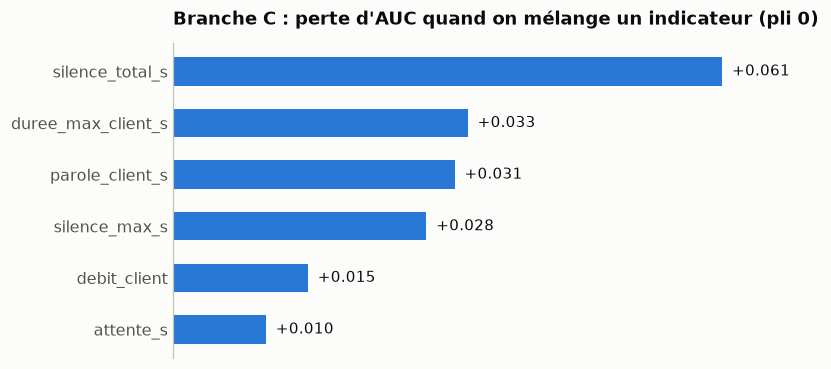

In [71]:
from sklearn.inspection import permutation_importance

entrainement, test = plis[0]
modele_C = modele_tableau().fit(X_C.iloc[entrainement], y[entrainement])
permutation = permutation_importance(modele_C, X_C.iloc[test], y[test], scoring="roc_auc", n_repeats=20, random_state=0)
importance = pd.Series(permutation.importances_mean, index=X_C.columns).sort_values(ascending=False)
tracer_barres(importance.head(6), "Branche C : perte d'AUC quand on mélange un indicateur (pli 0)", format_valeur="{:+.3f}")

**Réflexion 6.3.** La branche C fait-elle mieux que le repère « motif seul » ? Les indicateurs les plus importants te semblent-ils parler de tonalité, ou d'autre chose ?

In [72]:
# Les indicateurs de la branche C suffisent-ils à deviner le motif de l'appel ?
exactitude_motif = cross_val_score(modele_tableau(), X_C, appels.motif, cv=plis).mean()
print(f"motif deviné à partir des indicateurs de C : {exactitude_motif:.0%} (en répondant toujours le motif le plus fréquent : {appels.motif.value_counts(normalize=True).max():.0%})")
print("\ntotal des silences, moyenne par motif (secondes) :")
print(X_C.silence_total_s.groupby(appels.motif).mean().sort_values().round(0).to_string())

motif deviné à partir des indicateurs de C : 54% (en répondant toujours le motif le plus fréquent : 14%)

total des silences, moyenne par motif (secondes) :
motif
get branch hours        15.0
replace card            18.0
check balance           22.0
reset password          25.0
transfer money          28.0
schedule appointment    28.0
order checks            32.0
pay bill                43.0


**Réponse.** Non : la branche C est au niveau du repère « motif seul ». Selon la composition des plis elle passe un peu au-dessus ou un peu en dessous, jamais nettement. Les indicateurs qui pèsent le plus sont le total des silences, la durée du plus long tour du client et sa quantité de parole. Les silences et la quantité de parole décrivent surtout la longueur de la tâche : la cellule ci-dessus montre que le total des silences triple entre une demande d'horaires et un paiement de facture, et que les indicateurs de C suffisent à deviner le motif plus d'une fois sur deux. La branche C retrouve le scénario par un autre chemin, pas la tonalité.

L'importance par permutation est calculée sur un seul pli de 300 appels environ : l'ordre exact des indicateurs peut changer d'un pli à l'autre. Elle donne une tendance, pas un classement définitif.

## Partie 7 : fusion tardive

Chaque branche a produit un score par appel. La fusion **tardive** apprend à combiner ces trois décisions avec un tout petit modèle : une régression logistique à trois variables. « Tardive » parce qu'on fusionne des scores, pas des descripteurs : les branches restent indépendantes jusqu'au bout.

Deux précautions.

- On transforme chaque score en **logit**, `log(p / (1 - p))`. Une probabilité vit entre 0 et 1, un logit sur toute la droite : c'est l'échelle sur laquelle une régression logistique additionne naturellement ses variables.
- La fusion est évaluée hors pli elle aussi, avec les mêmes plis. Petite approximation, habituelle : les scores sur lesquels elle s'entraîne viennent de modèles qui ont vu le pli de test pendant leur propre entraînement. Un protocole strict emboîterait deux validations croisées. L'effet est faible avec trois variables.

### Exercice 7.1 : la fusion

1. Écris `logit(p)`. Borne d'abord `p` entre 0,0001 et 0,9999 avec `np.clip`, sinon un score de 0 ou de 1 donne l'infini.
2. Écris `fusionner(*scores)` : elle empile les logits en colonnes et renvoie les scores hors pli d'une `LogisticRegression()`.
3. Calcule `scores_fusion` à partir de `scores_A`, `scores_B`, `scores_C`.

In [73]:
def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4)
    return np.log(p / (1 - p))

def fusionner(*scores):
    Z = np.column_stack([logit(s) for s in scores])
    return scores_hors_pli(LogisticRegression(), Z)

scores_fusion = fusionner(scores_A, scores_B, scores_C)
for nom, s in [("A, les mots", scores_A), ("B, la voix", scores_B), ("C, le déroulement", scores_C), ("Fusion A + B + C", scores_fusion)]:
    bilan(nom, s)

A, les mots                                AUC 0.849   précision moyenne 0.665
B, la voix                                 AUC 0.526   précision moyenne 0.277
C, le déroulement                          AUC 0.614   précision moyenne 0.339
Fusion A + B + C                           AUC 0.844   précision moyenne 0.655


In [74]:
# Vérification 7.1
verifier("logit(0,5) = 0 et logit(0,9) = 2,197", lambda: proche(logit(np.array([0.5]))[0], 0, 1e-9) and proche(logit(np.array([0.9]))[0], 2.1972, 1e-3),
         "np.log(p / (1 - p))")
verifier("logit reste fini pour 0 et 1", lambda: np.isfinite(logit(np.array([0.0, 1.0]))).all(), "np.clip(p, 1e-4, 1 - 1e-4) avant le logarithme")
verifier("fusionner accepte deux ou trois branches", lambda: fusionner(scores_A, scores_C).shape == (len(appels),) and scores_fusion.shape == (len(appels),),
         "np.column_stack([logit(s) for s in scores]) puis scores_hors_pli(LogisticRegression(), Z)")
verifier("la fusion travaille sur les logits, pas sur les probabilités",
         lambda: np.allclose(fusionner(scores_A, scores_C), scores_hors_pli(LogisticRegression(), np.column_stack([logit(scores_A), logit(scores_C)]))),
         "np.column_stack([logit(s) for s in scores]) : chaque colonne est le logit d'une branche")
verifier("AUC de la fusion proche de 0,84", lambda: proche(auc(scores_fusion), 0.844, 0.03))

[OK]        logit(0,5) = 0 et logit(0,9) = 2,197
[OK]        logit reste fini pour 0 et 1
[OK]        fusionner accepte deux ou trois branches
[OK]        la fusion travaille sur les logits, pas sur les probabilités
[OK]        AUC de la fusion proche de 0,84


### Exercice 7.2 : que pèse chaque branche ?

Entraîne la régression logistique de fusion sur tous les appels, à partir des logits des trois branches comme en 7.1, et range ses trois coefficients dans `poids`, une Series indexée par `"A, les mots"`, `"B, la voix"`, `"C, le déroulement"`. Trace-la avec `tracer_barres(poids, titre, format_valeur="{:+.2f}")`.

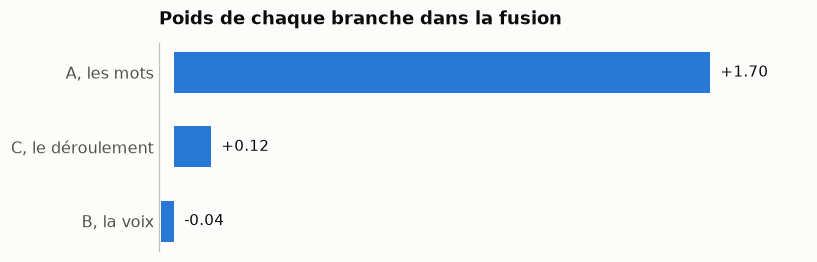

In [75]:
Z = np.column_stack([logit(s) for s in (scores_A, scores_B, scores_C)])
poids = pd.Series(LogisticRegression().fit(Z, y).coef_[0], index=["A, les mots", "B, la voix", "C, le déroulement"])
tracer_barres(poids, "Poids de chaque branche dans la fusion", format_valeur="{:+.2f}")

In [76]:
# Vérification 7.2
verifier("trois poids, un par branche", lambda: list(poids.index) == ["A, les mots", "B, la voix", "C, le déroulement"],
         "LogisticRegression().fit(Z, y).coef_[0]")
verifier("les poids sont appris sur les logits", lambda: np.allclose(poids.values, LogisticRegression().fit(np.column_stack([logit(s) for s in (scores_A, scores_B, scores_C)]), y).coef_[0], atol=1e-6),
         "Z = np.column_stack([logit(s) for s in (scores_A, scores_B, scores_C)]) puis LogisticRegression().fit(Z, y).coef_[0]")
verifier("la branche A porte l'essentiel du poids", lambda: poids.idxmax() == "A, les mots" and poids["A, les mots"] > 3 * abs(poids["B, la voix"]))

[OK]        trois poids, un par branche


[OK]        les poids sont appris sur les logits
[OK]        la branche A porte l'essentiel du poids


**Réflexion 7.2.** La fusion fait-elle mieux que la meilleure branche seule ? Que disent les poids ?

**Réponse.** Non. La fusion des trois branches fait même un peu moins bien que la branche A seule : quelques millièmes d'AUC en moins. Les poids expliquent pourquoi il n'y a rien à gagner : la fusion s'appuie presque entièrement sur A et donne aux deux autres un poids proche de zéro.

Ce n'est pas un échec de la fusion : elle a correctement appris que B et C n'apportent presque rien ici. Reste à savoir si ces quelques millièmes sont un vrai écart ou du bruit. C'est l'objet de la partie suivante.

Sur l'approximation signalée plus haut : pendant la préparation, un protocole strict à deux validations croisées emboîtées a donné 0,845 pour la fusion complète, contre 0,844 ici. L'approximation ne change donc pas la conclusion.

## Partie 8 : étude d'ablation

Une étude d'ablation retire des morceaux du système pour mesurer ce que chacun apporte. Ici : les sept combinaisons possibles de branches.

### Exercice 8.1 : les sept combinaisons

Construis :

- `scores_par_combinaison` : un dictionnaire dont les clés sont `"A"`, `"B"`, `"C"`, `"A + B"`, `"A + C"`, `"B + C"`, `"A + B + C"`. Une branche seule garde ses propres scores, une combinaison passe par `fusionner`.
- `ablation` : un tableau indexé par ces noms, avec les colonnes `AUC` et `précision moyenne`.

Indice : `itertools.combinations(["A", "B", "C"], 2)` énumère les paires.

In [77]:
branches = {"A": scores_A, "B": scores_B, "C": scores_C}
scores_par_combinaison = {}
for taille in (1, 2, 3):
    for combinaison in itertools.combinations(branches, taille):
        nom = " + ".join(combinaison)
        scores_par_combinaison[nom] = branches[combinaison[0]] if taille == 1 else fusionner(*[branches[b] for b in combinaison])

ablation = pd.DataFrame({
    "AUC": {nom: auc(s) for nom, s in scores_par_combinaison.items()},
    "précision moyenne": {nom: average_precision_score(y, s) for nom, s in scores_par_combinaison.items()},
})
ablation.round(3)

,AUC,précision moyenne
A,0.849,0.665
B,0.526,0.277
C,0.614,0.339
A + B,0.845,0.658
A + C,0.845,0.657
B + C,0.598,0.323
A + B + C,0.844,0.655


In [78]:
# Vérification 8.1
verifier("sept combinaisons", lambda: set(scores_par_combinaison) == {"A", "B", "C", "A + B", "A + C", "B + C", "A + B + C"},
         "\" + \".join(combinaison) pour chaque taille 1, 2, 3")
verifier("une branche seule garde ses scores", lambda: np.allclose(scores_par_combinaison["A"], scores_A))
verifier("tableau avec AUC et précision moyenne", lambda: set(ablation.index) == set(scores_par_combinaison) and {"AUC", "précision moyenne"} <= set(ablation.columns))
verifier("la ligne complète correspond à la fusion de la partie 7", lambda: proche(ablation.loc["A + B + C", "AUC"], auc(scores_fusion), 1e-6))

[OK]        sept combinaisons
[OK]        une branche seule garde ses scores
[OK]        tableau avec AUC et précision moyenne
[OK]        la ligne complète correspond à la fusion de la partie 7


### Exercice 8.2 : l'écart est-il réel ?

Deux AUC qui diffèrent de quelques millièmes ne prouvent rien. Il faut un **intervalle de confiance**. Le bootstrap en fabrique un sans supposer de loi particulière : on rejoue l'évaluation sur des centaines de jeux de données fictifs, tirés au hasard avec remise dans le nôtre, et on regarde entre quelles valeurs le résultat se promène.

Comme les appels d'un même client se ressemblent, on tire des **clients entiers**, pas des appels.

Écris `ic_bootstrap(statistique, n_tirages=500, graine=0)` (« ic » pour intervalle de confiance) :

1. prépare, pour chaque client, les positions de ses appels (`np.flatnonzero(ids == i)`) ;
2. à chaque tirage, choisis autant de clients qu'il y en a, avec remise (`rng.choice`), et mets bout à bout les positions de leurs appels ;
3. applique `statistique` à ces positions et garde la valeur ;
4. renvoie les percentiles 2,5 et 97,5 des valeurs.

`statistique` est une fonction qui reçoit un tableau de positions `i` et renvoie un nombre. Par exemple, `lambda i: roc_auc_score(y[i], scores_A[i])` donne l'intervalle de l'AUC de la branche A.

Puis calcule `gain`, la différence d'AUC entre `"A + B + C"` et `"A"`, et son intervalle `ic_gain`. Pour un écart entre deux systèmes, la statistique est **la différence des deux AUC calculées sur le même tirage**. C'est ce qu'on appelle un bootstrap apparié : les deux systèmes sont jugés sur les mêmes appels à chaque tirage, et l'intervalle porte directement sur l'écart. Soustraire les bornes de deux intervalles calculés séparément ne donne pas la même chose.

In [79]:
def ic_bootstrap(statistique, n_tirages=500, graine=0):
    """Intervalle à 95 % d'une statistique. statistique reçoit un tableau de positions d'appels et renvoie un nombre."""
    rng = np.random.default_rng(graine)
    ids = appels.id_client.values
    positions = {i: np.flatnonzero(ids == i) for i in np.unique(ids)}
    cles = list(positions)
    valeurs = []
    for _ in range(n_tirages):
        tirage = np.concatenate([positions[i] for i in rng.choice(cles, size=len(cles), replace=True)])
        valeurs.append(statistique(tirage))
    return np.percentile(valeurs, [2.5, 97.5])

complet, seule = scores_par_combinaison["A + B + C"], scores_par_combinaison["A"]
gain = auc(complet) - auc(seule)
ic_gain = ic_bootstrap(lambda i: roc_auc_score(y[i], complet[i]) - roc_auc_score(y[i], seule[i]))
print(f"gain de la fusion complète sur A seule : {gain:+.4f}, intervalle à 95 % [{ic_gain[0]:+.4f} ; {ic_gain[1]:+.4f}]")

gain de la fusion complète sur A seule : -0.0051, intervalle à 95 % [-0.0099 ; +0.0003]


In [80]:
# Vérification 8.2
verifier("un intervalle de deux bornes croissantes", lambda: len(ic_gain) == 2 and ic_gain[0] < ic_gain[1], "np.percentile(valeurs, [2.5, 97.5])")
verifier("l'intervalle d'une constante est réduit à cette constante", lambda: np.allclose(ic_bootstrap(lambda i: 1.0, n_tirages=20), [1.0, 1.0]))
verifier("le tirage se fait par client : la taille de l'échantillon varie d'un tirage à l'autre",
         lambda: (lambda bornes: bornes[0] < bornes[1])(ic_bootstrap(lambda i: float(len(i)), n_tirages=50)),
         "tire des identifiants de clients avec rng.choice(cles, size=len(cles), replace=True), puis concatène leurs positions")
verifier("même graine, même résultat", lambda: np.allclose(ic_bootstrap(lambda i: float(y[i].mean()), 50, 1), ic_bootstrap(lambda i: float(y[i].mean()), 50, 1)),
         "np.random.default_rng(graine)")
verifier("le gain observé est dans son intervalle", lambda: ic_gain[0] <= gain <= ic_gain[1], "gain = auc(complet) - auc(seule)")
verifier("l'intervalle du gain est apparié : une seule statistique, la différence des deux AUC sur le même tirage",
         lambda: np.allclose(ic_gain, ic_bootstrap(lambda i: roc_auc_score(y[i], complet[i]) - roc_auc_score(y[i], seule[i])), atol=0.0015),
         "ic_bootstrap(lambda i: roc_auc_score(y[i], complet[i]) - roc_auc_score(y[i], seule[i])), avec les valeurs par défaut de n_tirages et graine")
verifier("la fusion complète ne fait pas nettement mieux que A seule", lambda: gain < 0.01 and ic_gain[1] < 0.02)

[OK]        un intervalle de deux bornes croissantes
[OK]        l'intervalle d'une constante est réduit à cette constante
[OK]        le tirage se fait par client : la taille de l'échantillon varie d'un tirage à l'autre
[OK]        même graine, même résultat
[OK]        le gain observé est dans son intervalle


[OK]        l'intervalle du gain est apparié : une seule statistique, la différence des deux AUC sur le même tirage
[OK]        la fusion complète ne fait pas nettement mieux que A seule


La cellule suivante calcule l'intervalle de chaque combinaison avec ta fonction et trace le résultat.

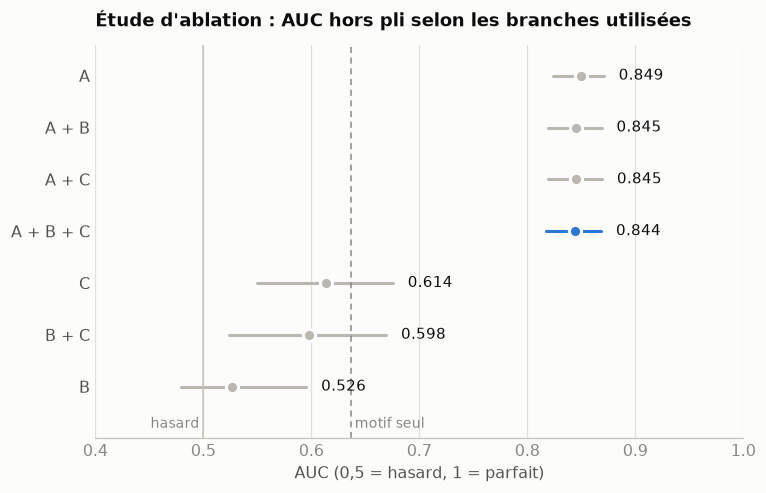

repère « motif seul » : AUC 0.637


,AUC,précision moyenne,bas,haut
A,0.849,0.665,0.824,0.871
A + B,0.845,0.658,0.819,0.869
A + C,0.845,0.657,0.819,0.869
A + B + C,0.844,0.655,0.817,0.868
C,0.614,0.339,0.550,0.675
B + C,0.598,0.323,0.524,0.669
B,0.526,0.277,0.479,0.595


In [81]:
intervalles = {nom: ic_bootstrap(lambda i, s=s: roc_auc_score(y[i], s[i])) for nom, s in scores_par_combinaison.items()}
ablation["bas"] = [intervalles[nom][0] for nom in ablation.index]
ablation["haut"] = [intervalles[nom][1] for nom in ablation.index]
tracer_ablation(ablation, repere=auc(scores_motif))
print(f"repère « motif seul » : AUC {auc(scores_motif):.3f}")
ablation.sort_values("AUC", ascending=False).round(3)

**Réflexion 8.2.** Quelles branches gardes-tu ? Justifie avec les intervalles. Ta conclusion vaut-elle pour tout projet d'analyse d'appels ?

In [82]:
# D'où viennent les millièmes perdus par la fusion ? On « fusionne » la branche A toute seule :
# chaque pli apprend alors sa propre échelle de score, sans aucune information nouvelle.
print(f"A seule, scores d'origine           : AUC {auc(scores_A):.4f}")
print(f"A seule, passée par la fusion       : AUC {auc(fusionner(scores_A)):.4f}")
print(f"fusion complète A + B + C           : AUC {auc(scores_fusion):.4f}")

A seule, scores d'origine           : AUC 0.8494
A seule, passée par la fusion       : AUC 0.8472
fusion complète A + B + C           : AUC 0.8443


**Réponse.** On garde A seule. Les quatre combinaisons qui contiennent A sont au même niveau et leurs intervalles se recouvrent presque entièrement. Le gain de la fusion complète sur A seule est légèrement négatif, et son intervalle va d'environ -0,010 à une valeur collée à zéro : au mieux la fusion fait jeu égal, plus probablement elle fait un peu moins bien. B seule est au niveau du hasard, C seule au niveau du repère « motif seul ». Ajouter deux branches voudrait dire plus de calcul, plus de code à maintenir et plus de données personnelles traitées (la voix), pour aucun gain mesurable.

Pourquoi la fusion peut-elle faire moins bien que sa meilleure branche ? Deux petites causes s'additionnent. D'abord, chaque pli apprend sa propre fusion, donc sa propre échelle de score : quand on rassemble les cinq plis pour calculer l'AUC, ces échelles légèrement différentes brouillent un peu le classement. La cellule ci-dessus le montre : A seule, passée par la fusion, perd déjà quelques millièmes. Ensuite, les poids donnés à B et C sont faibles mais pas nuls : ils ajoutent du bruit sans information.

Cette conclusion vaut pour **ce corpus et cette étiquette**. L'étiquette vient d'un outil qui semble lire surtout les mots, il est donc logique que les mots suffisent à la retrouver. Les études sur de vraies annotations de satisfaction ne sont pas unanimes. Sur le corpus français AlloSat, le texte fait mieux que la voix et leur fusion n'apporte rien sur le jeu de test (Macary et al.). Sur d'autres appels réels, Chowdhury et al. trouvent au contraire que des descripteurs de tours de parole prédisent mieux la satisfaction que la prosodie ou les mots. La seule règle générale est la méthode : mesurer chaque branche seule, puis les combinaisons, avec des intervalles et un découpage par locuteur, avant de décider.

### Exercice 8.3 (bonus) : où se joue l'appel ?

Peut-on suivre la tonalité au fil de l'appel, début, milieu, fin ? Voici une façon simple d'obtenir cette **trajectoire** avec la branche A.

1. Découpe les tours du client (avec parole) en trois tiers selon leur position dans l'appel.
2. Pour chaque pli, entraîne `modele_texte()` sur le texte complet des appels d'entraînement, puis applique-le au texte de chaque tiers des appels de test.
3. Tu obtiens `proba_tiers` : une ligne par appel, trois colonnes `début`, `milieu`, `fin`.
4. Compare la moyenne de chaque colonne pour les appels étiquetés 1 et les autres, et l'AUC obtenue avec un seul tiers.

Deux indices. `bornes` a une ligne par appel alors que `tc` a une ligne par tour : `tc.sid.map(bornes["min"])` donne à chaque tour le début de son appel. Et certains appels n'ont aucun tour du client dans un tiers donné : après le regroupement, `.reindex(appels.index).fillna("")` leur donne un texte vide.

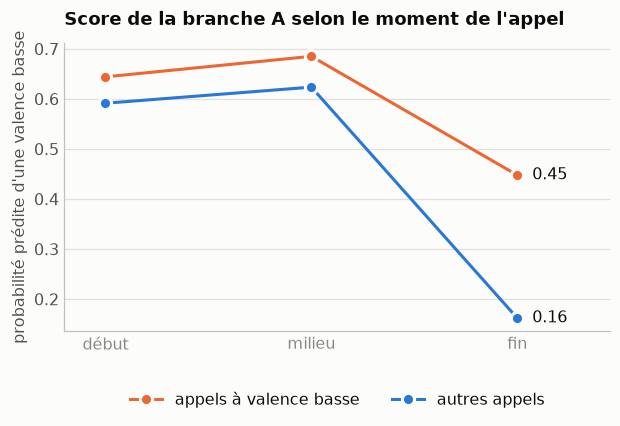

                        début  milieu   fin
appels à valence basse   0.64    0.69  0.45
autres appels            0.59    0.62  0.16
AUC en ne lisant qu'un tiers de l'appel : {'début': 0.603, 'milieu': 0.615, 'fin': 0.833}


In [83]:
tc = tours[(tours.role == "client") & tours.parole].copy()
bornes = tours[tours.parole].groupby("sid").debut_s.agg(["min", "max"])
position = (tc.debut_s - tc.sid.map(bornes["min"])) / (tc.sid.map(bornes["max"]) - tc.sid.map(bornes["min"])).clip(lower=1e-9)
tc["tiers"] = pd.cut(position, [-0.01, 1 / 3, 2 / 3, 1.01], labels=["début", "milieu", "fin"]).astype(str)

def texte_du_tiers(tiers):
    brut = tc[tc.tiers == tiers].groupby("sid").texte_auto.agg(" ".join).reindex(appels.index).fillna("")
    return pd.Series({sid: anonymiser(nettoyer(brut[sid]), [appels.nom_client[sid], appels.nom_conseiller[sid]]) for sid in appels.index})

textes_tiers = {tiers: texte_du_tiers(tiers) for tiers in ("début", "milieu", "fin")}
proba_tiers = pd.DataFrame(index=appels.index, columns=list(textes_tiers), dtype=float)
for entrainement, test in plis:
    modele = modele_texte().fit(texte_anonyme.iloc[entrainement], y[entrainement])
    for tiers, textes in textes_tiers.items():
        proba_tiers.iloc[test, proba_tiers.columns.get_loc(tiers)] = modele.predict_proba(textes.iloc[test])[:, 1]

trajectoire = pd.DataFrame({"appels à valence basse": proba_tiers[y == 1].mean(), "autres appels": proba_tiers[y == 0].mean()})
tracer_trajectoire(trajectoire, "Score de la branche A selon le moment de l'appel", "probabilité prédite d'une valence basse")
print(trajectoire.round(2).T.to_string())
auc_par_tiers = pd.Series({tiers: auc(proba_tiers[tiers].values) for tiers in proba_tiers.columns})
print("AUC en ne lisant qu'un tiers de l'appel :", auc_par_tiers.round(3).to_dict())

In [84]:
# Vérification 8.3
verifier("une probabilité par appel et par tiers", lambda: proba_tiers.shape == (len(appels), 3) and proba_tiers.notna().all().all() and proba_tiers.values.min() >= 0)
verifier("c'est la fin de l'appel qui sépare le mieux les deux groupes", lambda: auc_par_tiers.idxmax() == "fin" and auc_par_tiers["fin"] > auc_par_tiers["début"] + 0.1,
         "le modèle s'entraîne sur texte_anonyme.iloc[entrainement] et prédit sur textes.iloc[test]")

[OK]        une probabilité par appel et par tiers
[OK]        c'est la fin de l'appel qui sépare le mieux les deux groupes


**Réflexion 8.3.** À quel moment de l'appel l'étiquette se décide-t-elle ? Qu'est-ce que cela dit de ce que mesure l'outil ?

**Réponse.** À la fin. En ne lisant que le dernier tiers de l'appel, on retrouve presque tout le score de la branche A, alors que le début et le milieu ne font pas mieux que le repère « motif seul ». Pour les appels ordinaires, la probabilité prédite s'effondre dans le dernier tiers : le client remercie chaleureusement et le modèle bascule. Pour les appels à valence basse, elle baisse aussi, mais deux à trois fois moins : le client conclut plus sèchement, ou pas du tout.

L'outil mesure donc surtout la façon dont le client prend congé. C'est une information réelle, car la manière dont un appel se termine compte dans l'expérience du client, mais c'est beaucoup plus étroit que « la satisfaction ».

## Partie 9 : la note laissée après l'appel

Le corpus contient une donnée qui ressemble beaucoup plus à de la satisfaction : après chaque appel, le client pouvait noter son interlocuteur de 0 à 10 (`note_client`). C'est l'équivalent d'une enquête envoyée après un appel réel. Pourquoi ne pas l'avoir utilisée comme étiquette ?

### Exercice 9.1 : regarder la note

Calcule `part_sans_note` (part des appels sans note) et `part_de_10` (part des notes égales à 10 parmi les appels notés). Trace la distribution des notes de 0 à 10 avec `tracer_colonnes`.

Indice : `tracer_colonnes` attend une Series dont l'index donne les catégories dans l'ordre. `value_counts()` puis `.reindex(range(11), fill_value=0)` fait apparaître les notes que personne n'a données.

33% des appels n'ont pas de note ; parmi les autres, 90% ont la note 10


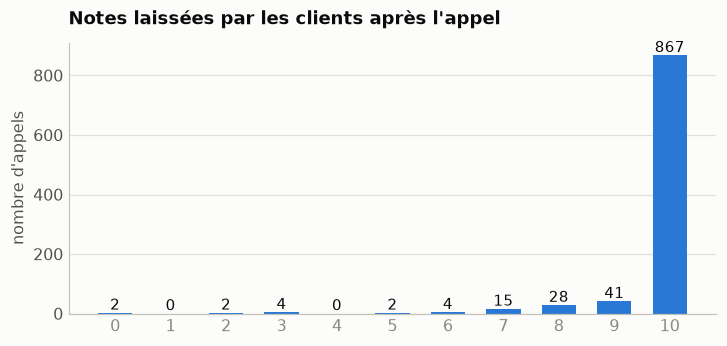

In [85]:
part_sans_note = float(appels.note_client.isna().mean())
notes = appels[appels.note_client.notna()]
part_de_10 = float((notes.note_client == 10).mean())
print(f"{part_sans_note:.0%} des appels n'ont pas de note ; parmi les autres, {part_de_10:.0%} ont la note 10")
tracer_colonnes(notes.note_client.astype(int).value_counts().reindex(range(11), fill_value=0),
                "Notes laissées par les clients après l'appel", ylabel="nombre d'appels")

In [86]:
# Vérification 9.1
verifier("un tiers des appels sans note", lambda: proche(part_sans_note, 481 / 1446, 0.002), "appels.note_client.isna().mean()")
verifier("965 appels notés", lambda: len(notes) == 965 and notes.note_client.notna().all(),
         "notes = appels[appels.note_client.notna()] : un tableau entier, pas seulement la colonne des notes")
verifier("neuf notes sur dix valent 10", lambda: proche(part_de_10, 867 / 965, 0.002), "(notes.note_client == 10).mean()")

[OK]        un tiers des appels sans note
[OK]        965 appels notés
[OK]        neuf notes sur dix valent 10


### Exercice 9.2 : qui donne les notes basses ?

Appelons « note basse » toute note inférieure à 10.

1. `y_note` : tableau de 0 et de 1 pour les appels notés (1 si la note est basse).
2. `par_noteur` : pour chaque client, la part de notes basses qu'il a données (`mean`) et son nombre d'appels notés (`size`).
3. `n_jamais` : le nombre de clients qui n'ont jamais donné de note basse.

98 notes basses sur 965 ; 47 clients ont noté, 24 n'ont jamais donné de note basse, 8 en donnent plus d'une fois sur deux


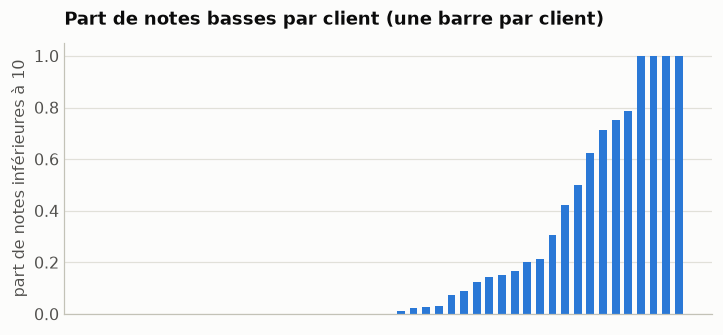

In [87]:
y_note = (notes.note_client < 10).astype(int).values
par_noteur = notes.assign(basse=y_note).groupby("id_client").basse.agg(["mean", "size"])
n_jamais = int((par_noteur["mean"] == 0).sum())
n_souvent = int((par_noteur["mean"] > 0.5).sum())
print(f"{y_note.sum()} notes basses sur {len(y_note)} ; {len(par_noteur)} clients ont noté, {n_jamais} n'ont jamais donné de note basse, "
      f"{n_souvent} en donnent plus d'une fois sur deux")
tracer_colonnes(par_noteur["mean"].sort_values().reset_index(drop=True), "Part de notes basses par client (une barre par client)",
                ylabel="part de notes inférieures à 10", etiquettes=False)

In [88]:
# Vérification 9.2
verifier("98 notes basses", lambda: int(y_note.sum()) == 98 and len(y_note) == 965, "(notes.note_client < 10).astype(int).values")
verifier("47 clients ont noté", lambda: len(par_noteur) == 47 and {"mean", "size"} <= set(par_noteur.columns),
         "notes.assign(basse=y_note).groupby(\"id_client\").basse.agg([\"mean\", \"size\"])")
verifier("24 clients n'ont jamais donné de note basse", lambda: n_jamais == 24)

[OK]        98 notes basses
[OK]        47 clients ont noté
[OK]        24 clients n'ont jamais donné de note basse


### Exercice 9.3 : peut-on prédire la note basse ?

Entraîne `modele_texte()` à prédire `y_note` à partir du texte anonymisé des appels notés, et mesure l'AUC hors pli de deux façons : découpage au hasard (`auc_note_hasard`), puis découpage par locuteur (`auc_note_locuteur`).

Attention : `scores_hors_pli`, `auc` et `bilan` utilisent l'étiquette `y` de tous les appels. Ici la cible et le sous-ensemble changent : calcule l'AUC avec `roc_auc_score(y_note, ...)` et appelle directement `cross_val_predict(..., method="predict_proba")`, avec `cv=StratifiedKFold(5, shuffle=True, random_state=0)` pour le découpage au hasard, puis `cv=StratifiedGroupKFold(5, shuffle=True, random_state=0)` et `groups=notes.id_client` pour le découpage par locuteur.

In [89]:
textes_notes = texte_anonyme[notes.index]
s_hasard = cross_val_predict(modele_texte(), textes_notes, y_note, method="predict_proba",
                             cv=StratifiedKFold(5, shuffle=True, random_state=0))[:, 1]
s_locuteur = cross_val_predict(modele_texte(), textes_notes, y_note, method="predict_proba", groups=notes.id_client,
                               cv=StratifiedGroupKFold(5, shuffle=True, random_state=0))[:, 1]
auc_note_hasard, auc_note_locuteur = roc_auc_score(y_note, s_hasard), roc_auc_score(y_note, s_locuteur)
print(f"prédire une note basse à partir des mots du client : AUC {auc_note_hasard:.3f} au hasard, {auc_note_locuteur:.3f} par locuteur")

prédire une note basse à partir des mots du client : AUC 0.793 au hasard, 0.548 par locuteur


In [90]:
# Vérification 9.3
verifier("AUC au hasard proche de 0,79", lambda: proche(auc_note_hasard, 0.793, 0.04),
         "cross_val_predict(modele_texte(), textes_notes, y_note, cv=StratifiedKFold(5, shuffle=True, random_state=0), method=\"predict_proba\")[:, 1]")
verifier("AUC par locuteur proche du hasard (entre 0,42 et 0,66)", lambda: 0.42 <= auc_note_locuteur <= 0.66,
         "même appel avec cv=StratifiedGroupKFold(5, shuffle=True, random_state=0) et groups=notes.id_client")
verifier("le découpage par locuteur fait chuter le score", lambda: auc_note_hasard > auc_note_locuteur + 0.04)

[OK]        AUC au hasard proche de 0,79
[OK]        AUC par locuteur proche du hasard (entre 0,42 et 0,66)
[OK]        le découpage par locuteur fait chuter le score


**Réflexion 9.3.** Résume en trois points pourquoi cette note, pourtant donnée par un humain, ne peut pas servir telle quelle d'étiquette de satisfaction. Que ferais-tu dans un vrai projet ?

**Réponse.** 1. **Elle manque souvent.** Un tiers des appels n'a pas de note, et rien ne garantit que ceux qui notent ressemblent à ceux qui ne notent pas.
2. **Elle est presque toujours maximale.** Neuf notes sur dix valent 10 : il reste une centaine de notes basses pour apprendre.
3. **Elle dépend surtout de celui qui note.** La moitié des clients ne donne jamais de note basse, une poignée en donne presque toujours. La note décrit le noteur plus que l'appel. D'où le résultat : avec un découpage au hasard, le modèle semble prédire la note parce qu'il reconnaît les noteurs sévères ; avec un découpage par locuteur, il ne reste presque rien.

Ce sont exactement les défauts connus des enquêtes de satisfaction réelles : peu de réponses, notes très déséquilibrées, forte subjectivité. Dans un vrai projet, la note d'enquête sert d'indice, pas de vérité. On fait annoter quelques centaines d'appels par deux personnes avec une consigne écrite, on mesure leur accord, et c'est ce jeu de référence qui sert à évaluer. La note d'enquête peut ensuite aider à choisir quels appels annoter en priorité.

## Partie 10 : avec une carte graphique, les modèles pré-entraînés

**Cette partie n'a pas été exécutée en entier lors de la préparation du corrigé**, faute de carte graphique et d'accès aux modèles : les cellules qui en dépendent n'affichent aucun résultat. Ce qui a tourné : la normalisation des textes de l'exercice 10.1 (sa sortie est affichée), et la suite de l'exercice 10.2 (mise en tableau, classifieur) avec des vecteurs factices à la place du vrai modèle. Le chargement des modèles et leurs résultats n'ont pas été vérifiés. Sur Kaggle, choisis l'accélérateur GPU T4 et relance le notebook : ces cellules s'exécuteront.

In [91]:
try:
    import torch
    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
print("carte graphique disponible :", GPU)

carte graphique disponible : False


### Exercice 10.1 : refaire la transcription avec Whisper

Transcris toi-même les tours du client de 100 appels et compare ton taux d'erreur à celui de la transcription fournie.

**Comparer équitablement.** Whisper écrit « 925 Main Street. » là où la référence humaine écrit « nine twenty five main street ». Sans précaution, chaque nombre compterait comme une erreur. L'usage, depuis l'article qui a présenté Whisper, est de passer la référence et la transcription dans le même **normaliseur** avant de compter les erreurs : minuscules, ponctuation retirée, mots d'hésitation retirés, nombres convertis en chiffres. Les heures et les numéros de téléphone restent pourtant écrits de plusieurs façons. On retire donc en plus tous les nombres : la comparaison porte sur les mots, pas sur les chiffres.

La cellule suivante prépare ce normaliseur et l'applique déjà à la transcription fournie avec le corpus. Elle tourne sans carte graphique.

In [92]:
try:
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")                       # messages d'accueil de la bibliothèque
        from transformers.models.whisper.english_normalizer import EnglishTextNormalizer
    normaliseur_whisper = EnglishTextNormalizer({})
except ImportError:
    normaliseur_whisper = None
    print("bibliothèque transformers absente : la partie 10 ne peut pas tourner ici")

def normaliser(texte):
    """Normalisation de Whisper pour l'anglais, puis retrait de tout ce qui contient un chiffre."""
    return " ".join(mot for mot in normaliseur_whisper(texte).split() if not any(caractere.isdigit() for caractere in mot))

if normaliseur_whisper is not None:
    for phrase in ("my address is nine twenty five main street", "My address is 925 Main Street.", "[noise] um yes, thank you!"):
        print(f"{phrase!r:48} devient {normaliser(phrase)!r}")

    echantillon_w = appels.sample(100, random_state=0).index
    tours_w = tours[tours.sid.isin(echantillon_w) & (tours.role == "client") & tours.parole & (tours.duree_s >= 0.4)]
    ref_w = tours_w.texte.map(normaliser)                    # la référence humaine, normalisée
    hyp_corpus = tours_w.texte_auto.map(normaliser)          # la transcription fournie avec le corpus, normalisée
    garder_w = ref_w != ""
    taux_erreur_corpus = jiwer.wer(ref_w[garder_w].tolist(), hyp_corpus[garder_w].tolist())
    print(f"\n{len(tours_w)} tours du client dans 100 appels, dont {garder_w.sum()} avec une référence non vide")
    print(f"transcription fournie avec le corpus : {taux_erreur_corpus:.1%} d'erreur de mots après normalisation")

'my address is nine twenty five main street'     devient 'my address is main street'
'My address is 925 Main Street.'                 devient 'my address is main street'
'[noise] um yes, thank you!'                     devient 'yes thank you'

630 tours du client dans 100 appels, dont 530 avec une référence non vide
transcription fournie avec le corpus : 8.5% d'erreur de mots après normalisation


À toi pour Whisper.

1. Crée le pipeline : `pipeline("automatic-speech-recognition", model="openai/whisper-large-v3-turbo", device=0)`.
2. Prépare une liste d'entrées `{"raw": signal, "sampling_rate": 16000}`, une par tour de `tours_w`, avec `signal_du_tour`.
3. Appelle le pipeline sur la liste avec `batch_size=16` et `generate_kwargs={"language": "english", "task": "transcribe"}`. Chaque sortie est un dictionnaire dont la clé `"text"` contient la transcription.
4. Normalise les sorties avec `normaliser` et range-les dans `hyp_whisper`, une Series indexée comme `tours_w`.
5. Calcule `taux_erreur_whisper` sur les tours de `garder_w`, comme pour `taux_erreur_corpus`.

In [93]:
if GPU:
    from transformers import pipeline

    whisper = pipeline("automatic-speech-recognition", model="openai/whisper-large-v3-turbo", device=0)
    entrees = [{"raw": signal_du_tour(tour), "sampling_rate": 16000} for tour in tours_w.itertuples()]
    debut = time.time()
    sorties = whisper(entrees, batch_size=16, generate_kwargs={"language": "english", "task": "transcribe"})
    print(f"{len(entrees)} tours transcrits en {time.time() - debut:.0f} s")

    hyp_whisper = pd.Series([normaliser(sortie["text"]) for sortie in sorties], index=tours_w.index)
    taux_erreur_whisper = jiwer.wer(ref_w[garder_w].tolist(), hyp_whisper[garder_w].tolist())
    print(f"taux d'erreur de mots après normalisation : Whisper {taux_erreur_whisper:.1%}, transcription fournie {taux_erreur_corpus:.1%}")
    display(pd.DataFrame({"référence": ref_w, "Whisper": hyp_whisper})[garder_w & (ref_w != hyp_whisper)].head(12))
    print("Tours dont la référence ne contient aucun mot : qu'écrit Whisper ?")
    display(pd.DataFrame({"référence brute": tours_w.texte, "Whisper": hyp_whisper})[~garder_w].head(12))
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


In [94]:
# Vérification 10.1
if GPU:
    verifier("une transcription par tour", lambda: len(hyp_whisper) == len(tours_w) and (hyp_whisper.str.len() > 0).mean() > 0.8,
             "pd.Series([normaliser(sortie[\"text\"]) for sortie in sorties], index=tours_w.index)")
    verifier("taux d'erreur de Whisper plausible (entre 0 et 50 %)", lambda: 0 < taux_erreur_whisper < 0.5,
             "au-delà de 50 %, vérifie la fréquence d'échantillonnage (16 000) et la langue")
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


**Réflexion 10.1.** Lis une douzaine de tours où Whisper et la référence diffèrent. Quels types d'erreurs vois-tu ? Dans le second tableau, Whisper invente-t-il parfois du texte sur un tour où l'annotateur n'a entendu aucun mot ?

**Réponse.** À vérifier sur ta propre exécution, la transcription par Whisper n'ayant pas tourné pendant la préparation. Ce qu'on observe en général avec Whisper sur de la parole téléphonique courte :

- des noms propres et des noms de lieux mal orthographiés, sans conséquence pour la suite puisqu'on les masque ;
- des petits mots d'écoute (« okay », « yeah ») omis ou ajoutés, alors que la référence humaine ne les note pas toujours non plus (exercice 1.6) ;
- sur des tours très courts ou bruités, du texte inventé. Les formules de politesse comme « thank you » font partie des hallucinations de Whisper les plus souvent rapportées sur du silence, ce qui est gênant ici puisque c'est précisément le signal qu'utilise la branche A.

D'où l'intérêt de ne transcrire que les tours qui contiennent de la parole, et de mesurer le taux d'erreur sur ses propres données au lieu de se fier aux chiffres publiés. Garde aussi en tête la limite de la comparaison : les nombres en sont exclus, et le normaliseur retire les mots d'hésitation des deux côtés.

### Exercice 10.2 : un encodeur de voix pré-entraîné à la place d'eGeMAPS

eGeMAPS résume la voix par 88 mesures choisies par des experts. Un encodeur comme **wav2vec 2.0** apprend ses propres représentations sur des milliers d'heures de parole. Il découpe le signal en **trames** de 20 millisecondes et produit un vecteur de 1 024 nombres par trame. La moyenne de ces vecteurs sur un tour de parole donne un **plongement** (*embedding*) : 1 024 nombres qui résument le tour. `facebook/wav2vec2-large-robust` a été pré-entraîné en partie sur de la parole téléphonique.

Ce modèle n'est distribué qu'au format `pytorch_model.bin`, que la bibliothèque `transformers` n'accepte de charger qu'avec PyTorch 2.6 ou plus récent (`torch.__version__` donne la version installée). Si le chargement est refusé, remplace `nom_encodeur` par `facebook/wav2vec2-base-960h` : un modèle plus petit (12 couches, 768 nombres par trame), distribué dans un format accepté par toutes les versions. Au chargement, un message peut signaler des poids non utilisés : c'est normal, ils ne servaient qu'au pré-entraînement.

**Première étape : le modèle et la fonction de plongement.**

1. Charge le préparateur et le modèle : `AutoFeatureExtractor.from_pretrained(nom_encodeur)` et `AutoModel.from_pretrained(nom_encodeur)`, envoyé sur la carte graphique (`.to("cuda")`), en mode évaluation (`.eval()`).
2. Écris `plongement(signal, couche=12)` : passe le signal dans le modèle avec `output_hidden_states=True`, prends dans `hidden_states` les états de la couche demandée (dimensions : 1, trames, 1 024) et renvoie leur moyenne sur les trames, sous forme de tableau numpy à une dimension. La couche 12 est au milieu des 24 couches du modèle : la réflexion 10.2 revient sur ce choix.

In [95]:
if GPU:
    from transformers import AutoFeatureExtractor, AutoModel

    nom_encodeur = "facebook/wav2vec2-large-robust"
    preparateur = AutoFeatureExtractor.from_pretrained(nom_encodeur)
    encodeur = AutoModel.from_pretrained(nom_encodeur).to("cuda").eval()

    @torch.no_grad()
    def plongement(signal, couche=12):
        entree = preparateur(signal, sampling_rate=16000, return_tensors="pt").input_values.to("cuda")
        etats = encodeur(entree, output_hidden_states=True).hidden_states[couche]      # dimensions : (1, trames, 1024)
        return etats.mean(dim=1).squeeze(0).float().cpu().numpy()

    print("un tour devient un vecteur de", plongement(signal_test).shape[0], "nombres")
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


In [96]:
# Vérification 10.2, première étape
if GPU:
    verifier("un vecteur numpy par tour, de la taille des états du modèle (1 024 pour le modèle proposé)",
             lambda: isinstance(plongement(signal_test), np.ndarray) and plongement(signal_test).shape == (encodeur.config.hidden_size,),
             "etats = encodeur(entree, output_hidden_states=True).hidden_states[couche] ; puis etats.mean(dim=1).squeeze(0).float().cpu().numpy()")
    verifier("la couche demandée change le résultat", lambda: not np.allclose(plongement(signal_test, couche=6), plongement(signal_test, couche=12)))
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


**Deuxième étape, fournie : tous les tours du client.** Comme en partie 5, le calcul est rangé dans un fichier et l'avancement s'affiche. Sur une carte T4, compte quelques minutes (durée non mesurée pendant la préparation).

In [97]:
def calculer_plongements(fonction, tours_a_traiter, fichier):
    """Applique fonction (signal -> vecteur) à chaque tour, range le résultat dans fichier, le relit s'il existe déjà."""
    if fichier.exists():
        print("relu depuis", fichier.name)
        return pd.read_pickle(fichier)
    debut, lignes = time.time(), {}
    for numero, tour in enumerate(tours_a_traiter.itertuples(), start=1):
        signal = signal_du_tour(tour)
        if len(signal) >= 0.3 * 16000:
            lignes[(tour.sid, tour.rang)] = fonction(signal)
        if numero % 1000 == 0:
            print(f"  {numero} tours sur {len(tours_a_traiter)}, {time.time() - debut:.0f} s écoulées")
    tableau = pd.DataFrame(list(lignes.values()), index=pd.MultiIndex.from_tuples(list(lignes), names=["sid", "rang"]))
    tableau.to_pickle(fichier)
    return tableau

if GPU:
    plongements = calculer_plongements(plongement, a_traiter, CACHE / "wav2vec_tours.pkl")
    print(plongements.shape[0], "tours x", plongements.shape[1], "dimensions")
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


**Troisième étape : un vecteur par appel, puis le classifieur.**

1. Résume chaque appel par la moyenne et le maximum de chaque dimension sur ses tours : `X_B2`, une ligne par appel dans l'ordre de `appels`, deux colonnes par dimension (2 048 avec le modèle proposé). Comme à l'exercice 5.3, aplatis les noms de colonnes en chaînes de caractères toutes différentes (par exemple `d17__mean`) : scikit-learn refuse les noms en double et les mélanges de nombres et de chaînes.
2. Calcule `scores_B2` (découpage par locuteur) et `scores_B2_hasard` (découpage au hasard) avec `modele_plongements()`, fourni : une normalisation suivie d'une régression logistique fortement régularisée, adaptée à 2 048 colonnes pour 1 446 appels.

In [98]:
if GPU:
    from sklearn.preprocessing import StandardScaler

    def modele_plongements():
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"))

    resume = plongements.groupby(level="sid").agg(["mean", "max"])
    resume.columns = [f"d{dimension}__{statistique}" for dimension, statistique in resume.columns]
    X_B2 = resume.reindex(appels.index)

    scores_B2 = scores_hors_pli(modele_plongements(), X_B2)
    scores_B2_hasard = scores_hors_pli(modele_plongements(), X_B2, plis_hasard)
    bilan("B, eGeMAPS, par locuteur", scores_B)
    bilan("B, wav2vec 2.0, par locuteur", scores_B2)
    bilan("B, wav2vec 2.0, au hasard", scores_B2_hasard)
    bilan("Fusion A + B (wav2vec 2.0) + C", fusionner(scores_A, scores_B2, scores_C))
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


In [99]:
# Vérification 10.2, troisième étape
if GPU:
    verifier("X_B2 : une ligne par appel, deux colonnes par dimension", lambda: X_B2.shape == (len(appels), 2 * plongements.shape[1]) and list(X_B2.index) == list(appels.index),
             "plongements.groupby(level=\"sid\").agg([\"mean\", \"max\"]), colonnes aplaties, puis .reindex(appels.index)")
    verifier("noms de colonnes en chaînes, tous différents", lambda: all(isinstance(c, str) for c in X_B2.columns) and X_B2.columns.is_unique)
    verifier("scores calculés", lambda: scores_B2.shape == (len(appels),) and 0.3 < auc(scores_B2) < 1)
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


**Réflexion 10.2.** L'encodeur pré-entraîné fait-il mieux qu'eGeMAPS avec le découpage par locuteur ? L'écart entre les deux découpages a-t-il disparu ? Un encodeur de parole capte aussi une partie des mots prononcés : en quoi cela complique-t-il l'interprétation d'une « branche voix » ?

**Réponse.** À vérifier sur ta propre exécution, cette partie n'ayant pas tourné pendant la préparation. Voici comment lire ce que tu obtiendras.

- Si wav2vec 2.0 dépasse nettement eGeMAPS par locuteur, ce n'est pas forcément grâce au ton de la voix. Ces encodeurs représentent aussi le contenu phonétique : ils « entendent » en partie les mots, et notre étiquette dépend des mots. La branche B deviendrait alors une branche A déguisée. Le test décisif est l'ablation : `A + B2` fait-il mieux que `A` seul, intervalle à l'appui ?
- L'écart entre découpage au hasard et par locuteur devrait rester : ces représentations caractérisent très bien la personne qui parle.
- Le choix de la couche compte. Les couches du milieu portent en général plus d'information sur la manière de parler que la dernière. Essaie `couche=6` et `couche=18` pour voir, en donnant un autre nom de fichier de cache à chaque essai.

### Exercice 10.3 : des plongements de phrases à la place du TF-IDF

Le TF-IDF compte des mots. Un modèle de **plongements de phrases** transforme un texte en vecteur qui représente son sens : « thanks a lot » et « thank you so much » deviennent voisins même sans mot commun.

1. Charge `SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device="cuda")`.
2. Encode `texte_anonyme` : `encodeur_texte.encode(liste_de_textes, batch_size=64, show_progress_bar=False)` renvoie un tableau numpy, une ligne par appel.
3. Calcule `scores_A2` avec le même petit modèle que pour wav2vec 2.0 (`modele_plongements`, redéfini ici pour que l'exercice reste indépendant).

In [100]:
if GPU:
    try:
        from sentence_transformers import SentenceTransformer
    except ImportError:
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sentence-transformers"], check=True)
        from sentence_transformers import SentenceTransformer
    from sklearn.preprocessing import StandardScaler

    def modele_plongements():
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.05, max_iter=3000, class_weight="balanced"))

    encodeur_texte = SentenceTransformer("sentence-transformers/all-mpnet-base-v2", device="cuda")
    X_A2 = encodeur_texte.encode(texte_anonyme.tolist(), batch_size=64, show_progress_bar=False)
    scores_A2 = scores_hors_pli(modele_plongements(), X_A2)
    bilan("A, TF-IDF", scores_A)
    bilan("A, plongements de phrases", scores_A2)
    bilan("Fusion des deux versions de A", fusionner(scores_A, scores_A2))
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


In [101]:
# Vérification 10.3
if GPU:
    verifier("un vecteur de 768 valeurs par appel", lambda: X_A2.shape == (len(appels), 768), "encodeur_texte.encode(texte_anonyme.tolist(), batch_size=64, show_progress_bar=False)")
    verifier("scores calculés", lambda: scores_A2.shape == (len(appels),) and 0.5 < auc(scores_A2) < 1)
else:
    print("partie ignorée : pas de carte graphique")

partie ignorée : pas de carte graphique


**Réflexion 10.3.** Les plongements font-ils mieux que le TF-IDF ? Dans quelle situation t'attendrais-tu à ce qu'ils fassent une vraie différence ?

**Réponse.** À vérifier sur ta propre exécution. Sur cette tâche, un écart faible ne serait pas surprenant : l'étiquette tient à quelques formules très répétées (remercier, prendre congé), que le TF-IDF capte parfaitement, et il y a 1 446 appels pour apprendre.

Les plongements, et plus encore un modèle affiné comme SetFit ou mmBERT, font la différence quand le sens ne tient pas à des mots fixes (ironie, reproche poli, problème décrit de mille façons), quand il y a peu d'exemples étiquetés, ou quand il faut couvrir plusieurs langues avec un seul modèle. Ce sont les conditions d'un vrai projet de satisfaction client, rarement celles d'un corpus scripté.

## Synthèse

Tu as construit le pipeline complet : contrôle à la réception, étiquette, découpage, trois branches, fusion, ablation. Trois questions pour faire le point.

**Bilan 1.** En une phrase par branche : qu'a donné A, qu'a donné B, qu'a donné C ?

**Réponse.** - **A, les mots** : la seule branche utile, très au-dessus du repère, et presque tout son signal vient de la fin de l'appel. Une partie de ce qu'elle apprenait venait d'un biais de l'étiquette sur les noms propres, retiré par l'anonymisation.
- **B, la voix** : au niveau du hasard dès qu'on évalue sur des clients jamais entendus ; son bon score apparent venait de la reconnaissance du locuteur.
- **C, le déroulement** : au niveau du repère « motif seul » ; elle retrouve le type d'appel, pas la tonalité.

**Bilan 2.** Un collègue t'annonce un classifieur de satisfaction avec une AUC de 0,90. Quelles questions lui poses-tu avant d'y croire ?

**Réponse.** 1. **D'où vient l'étiquette ?** Posée par des humains qui écoutent l'appel, tirée d'une enquête, ou produite par un outil ? Avec quel accord entre annotateurs ? Dépend-elle de ce qui ne devrait pas compter, comme le nom du client ?
2. **Comment sont séparés l'entraînement et le test ?** Un même client, un même conseiller peuvent-ils être des deux côtés ? Le test est-il postérieur à l'entraînement ?
3. **Quel est le repère ?** Que donne un modèle trivial (motif de l'appel, durée) sur le même test ?
4. **Que regarde le modèle ?** A-t-on inspecté les mots ou les variables qui pèsent le plus, pour repérer un raccourci ?
5. **Quel est l'intervalle de confiance ?** Sur combien d'appels et de clients ?

**Bilan 3.** Que faudrait-il changer pour refaire ce travail sur de vrais appels en français ?

**Réponse.** | Dans ce TP | Dans un vrai projet en français |
|---|---|
| Deux fichiers par appel, fournis | Stéréo : même principe. Mono : diarisation automatique (pyannote), avec ses erreurs à mesurer |
| Transcription automatique fournie, 6,5 % d'erreur | Whisper en version française (par exemple `bofenghuang/whisper-large-v3-french-distil-dec16`), taux d'erreur à mesurer sur 30 à 60 minutes transcrites à la main ; attendre plutôt 20 à 40 % |
| Noms connus par la fiche de l'appel | Outil d'anonymisation (Presidio configuré pour le français), contrôlé sur un échantillon |
| Étiquette déjà biaisée par les noms, masqués trop tard | Anonymiser avant tout outil d'analyse, et tester chaque outil en ne changeant que le nom dans une même phrase |
| TF-IDF et régression logistique | SetFit avec quelques dizaines d'exemples par classe, puis un encodeur affiné (mmBERT, CamemBERTa) |
| eGeMAPS | Encodeur de parole français (`LeBenchmark/wav2vec2-FR-7K-large`), seulement si l'ablation montre un gain |
| Étiquette d'un outil automatique | Jeu de référence de quelques centaines d'appels annotés par deux personnes, accord mesuré |
| Découpage par locuteur | Découpage par client, par conseiller et par date |
| Étiquette à deux classes | Trois classes (insatisfait, neutre, satisfait), avec le rappel sur « insatisfait » comme mesure principale |

La méthode, elle, ne change pas : contrôler ce qu'on reçoit, auditer l'étiquette, fermer les raccourcis, mesurer un repère, puis ajouter les branches une par une en vérifiant ce que chacune apporte.

### Sources

- Corpus : Wu, Nafziger, Scodary, Maas, *HarperValleyBank: A Domain-Specific Spoken Dialog Corpus*, 2020, [arXiv:2010.13929](https://arxiv.org/abs/2010.13929), [dépôt](https://github.com/cricketclub/gridspace-stanford-harper-valley), licence CC BY 4.0.
- Descripteurs acoustiques : Eyben et al., *The Geneva Minimalistic Acoustic Parameter Set (GeMAPS)*, 2016, calculés avec [openSMILE](https://github.com/audeering/opensmile-python).
- Texte contre voix sur des appels français annotés en satisfaction : Macary et al., 2023, [arXiv:2310.04481](https://arxiv.org/abs/2310.04481).
- Notes d'enquête après appel, subjectives et déséquilibrées : Bockhorst et al., 2017, [ECML PKDD](https://mlanthology.org/ecmlpkdd/2017/bockhorst2017ecmlpkdd-predicting).
- Tours de parole et satisfaction sur des appels réels : Chowdhury, Stepanov, Riccardi, *Predicting User Satisfaction from Turn-Taking in Spoken Conversations*, [Interspeech 2016](https://www.isca-archive.org/interspeech_2016/chowdhury16_interspeech.html).
- Taux d'erreur de Whisper sur des appels français de centre de contact : tests de l'auteur de [whisper-large-v3-french](https://huggingface.co/bofenghuang/whisper-large-v3-french), sur des jeux privés.
- Whisper et sa normalisation des textes avant le calcul du taux d'erreur : Radford et al., *Robust Speech Recognition via Large-Scale Weak Supervision*, 2022, [arXiv:2212.04356](https://arxiv.org/abs/2212.04356).